#Environment Setup

In [1]:
# Basic imports
import os
import json
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
print("Geopandas version:", gpd.__version__)
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from shapely.geometry import Point
from shapely.strtree import STRtree
from groq import Groq
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# Consistent plotting style
def apply_style():
    plt.rcParams.update({
        'figure.dpi': 120,
        'figure.titlesize': 16,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })
apply_style()



Geopandas version: 1.1.4


In [2]:
import sys
print(sys.executable)

C:\Users\User\anaconda3\python.exe


In [3]:
import geopandas as gpd
print("Geopandas version:", gpd.__version__)


Geopandas version: 1.1.4


#Data Acquisition

In [4]:
# Directory setup
# Directory setup
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

POI_FILE = DATA_DIR / 'osm_pois_manhattan.geojson'
NTA_FILE = DATA_DIR / 'manhattan_nta.geojson'

# Download POIs if not cached
if POI_FILE.exists():
    print(f"Loaded from cache: {POI_FILE.name}")
    pois = gpd.read_file(POI_FILE)[['geometry', 'amenity']]

else:
    print("Downloading Manhattan POIs from OSM (no cache found)...")
    raw_pois = ox.features_from_place(
        'Manhattan, New York City, New York, USA',
        tags={'amenity': True}
    )

    # Keep only point geometries
    pois = raw_pois[raw_pois.geometry.geom_type == 'Point'][['geometry', 'amenity']]

    # Save to cache
    pois.to_file(POI_FILE, driver='GeoJSON')

# Create a clean POI subset
pois_man = pois.copy()

print(f"POIs: {len(pois_man):,} points")
print(pois_man['amenity'].value_counts().head(10).to_string())


Loaded from cache: osm_pois_manhattan.geojson
POIs: 24,725 points
amenity
bench              6159
bicycle_parking    3676
restaurant         3411
waste_basket       1743
fast_food          1529
cafe               1241
bicycle_rental      680
bar                 660
drinking_water      521
post_box            499


#Neighbourhhod Boundaries

In [5]:
# Download NTAs if not cached
import requests

if NTA_FILE.exists():
    manhattan = gpd.read_file(NTA_FILE)
else:
    url = 'https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson'
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    nhoods_all = gpd.GeoDataFrame.from_features(response.json()['features'], crs=4326)
    manhattan = (
        nhoods_all[(nhoods_all['boroname'] == 'Manhattan') & (nhoods_all['ntatype'] == '0')]
        .copy()
        .reset_index(drop=True)
    )
    manhattan.to_file(NTA_FILE, driver='GeoJSON')

print(f"Manhattan NTAs: {len(manhattan)}")

Manhattan NTAs: 32


#Spatial Index

In [6]:
# Build STRtree index in EPSG:2263
pois_2263 = pois.to_crs(2263)
manhattan_2263 = manhattan.to_crs(2263)

poi_tree = STRtree(pois_2263.geometry)

def pois_in_polygon(polygon_2263):
    """Return POIs intersecting a polygon (EPSG:2263)."""
    idx = poi_tree.query(polygon_2263, predicate='intersects')
    return pois.iloc[idx]

def pois_near_point(lat, lon, radius_m):
    """Return POIs within radius_m meters of a lat/lon point."""
    pt = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(2263)
    buffer = pt.buffer(radius_m)
    idx = poi_tree.query(buffer.geometry[0], predicate='intersects')
    return pois.iloc[idx]


#Visualise POIs and NTA boundaries side by side


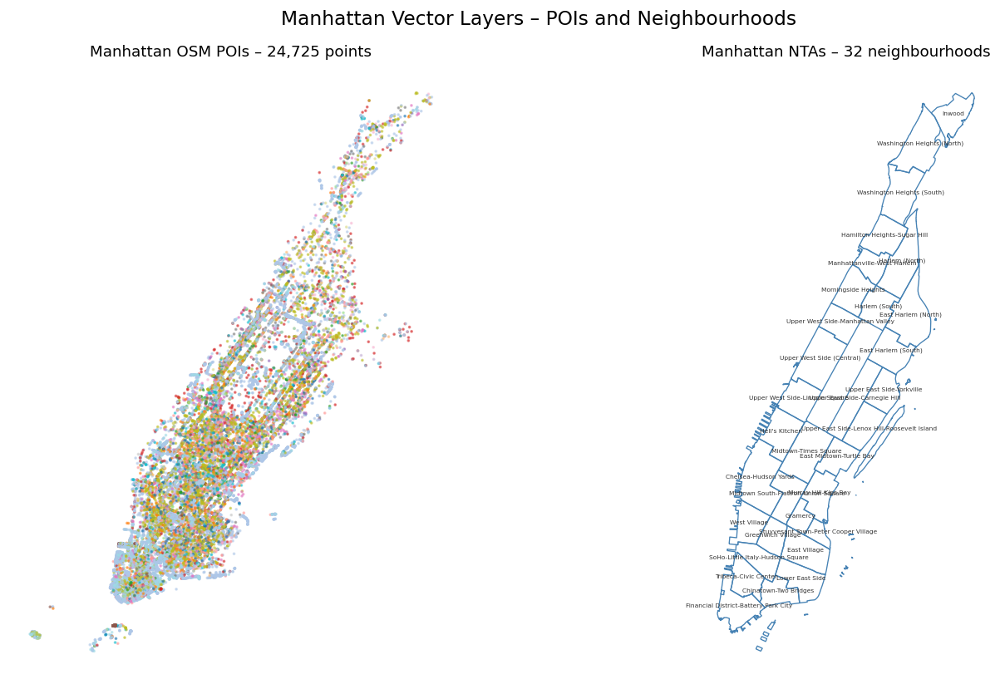

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# --- LEFT PLOT: POIs ---
pois_man.plot(
    ax=axes[0],
    markersize=1.5,
    alpha=0.5,
    column='amenity',
    legend=False,
    cmap='tab20'
)

axes[0].set_title(
    f"Manhattan OSM POIs – {len(pois_man):,} points",
    fontsize=11
)
axes[0].set_aspect('equal')
axes[0].axis('off')

# --- RIGHT PLOT: NTAs ---
manhattan.boundary.plot(
    ax=axes[1],
    linewidth=0.8,
    color='steelblue'
)

# Label each neighbourhood
manhattan.apply(
    lambda row: axes[1].annotate(
        row['ntaname'],
        xy=row.geometry.centroid.coords[0],
        ha='center',
        fontsize=4.5,
        color='#333333'
    ),
    axis=1
)

axes[1].set_title(
    f"Manhattan NTAs – {len(manhattan)} neighbourhoods",
    fontsize=11
)
axes[1].axis('off')

plt.suptitle(
    "Manhattan Vector Layers – POIs and Neighbourhoods",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [8]:
# Save POIs if file does not exist
if not POI_FILE.exists():
    pois_man.to_file(POI_FILE, driver='GeoJSON')

# Save NTAs if file does not exist
if not NTA_FILE.exists():
    manhattan.to_file(NTA_FILE, driver='GeoJSON')

# Print summary
print(f"POIs: {POI_FILE.name:30s} {len(pois_man):6,} points")
print(f"NTAs: {NTA_FILE.name:30s} {len(manhattan):6,} polygons")


POIs: osm_pois_manhattan.geojson     24,725 points
NTAs: manhattan_nta.geojson              32 polygons


#Shared helper:annotate NTA map with neighbouhood names

In [9]:
def annotate_ntas(ax, gdf, fontsize=4.5, color='#333333'):
    """
    Label each NTA polygon at its centroid.
    """
    for _, row in gdf.iterrows():
        # Get centroid coordinates
        cx, cy = row.geometry.centroid.coords[0]

        # Add annotation
        ax.annotate(
            row['ntaname'],
            xy=(cx, cy),
            ha='center',
            va='center',
            fontsize=fontsize,
            color=color,
        )


#load and inpect Manhattan NTA polygons

In [10]:
manhattan = gpd.read_file(NTA_FILE).to_crs(4326)

print(f"NTAs: {len(manhattan)}")
print(f"CRS: {manhattan.crs}")
print(f"Columns: {list(manhattan.columns)}")

print()
print("Area range (km²):")

NTAs: 32
CRS: EPSG:4326
Columns: ['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname', 'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020', 'geometry']

Area range (km²):


In [11]:
# EPSG:2263 – NY State Plane (Long Island), US survey feet
# Used as canonical metric CRS for NYC spatial analysis

manhattan_proj = manhattan.to_crs(2263)

# Compute area in km²
FT2_PER_M2 = 10.7639
areas_ft2 = manhattan_proj.geometry.area
areas_m2 = areas_ft2 / FT2_PER_M2
areas_km2 = areas_m2 / 1e6

print(f"min: {areas_km2.min():.2f} km²")
print(f"max: {areas_km2.max():.2f} km²")
print(f"median: {areas_km2.median():.2f} km²")

print()
print(manhattan[['nta2020', 'ntaname']].head(10).to_string(index=False))


min: 0.52 km²
max: 2.76 km²
median: 1.47 km²

nta2020                              ntaname
 MN0101 Financial District-Battery Park City
 MN0102                 Tribeca-Civic Center
 MN0201      SoHo-Little Italy-Hudson Square
 MN0202                    Greenwich Village
 MN0203                         West Village
 MN0301                Chinatown-Two Bridges
 MN0302                      Lower East Side
 MN0303                         East Village
 MN0401                 Chelsea-Hudson Yards
 MN0402                       Hell's Kitchen


In [12]:
#Verify NTA composition composition matches what the guide assumes
#Cross-check the schema the rest of the guide assumes
#Fail loudly if anything has drifted


# Expected columns for Manhattan NTA file
expected_columns = {
    'shape_area', 'ntaname', 'cdtaname', 'boroname',
    'ntatype', 'nta2020', 'borocode', 'countyfips',
    'ntaabbrev', 'cdta2020', 'geometry'
}

# Validate number of NTAs
assert len(manhattan) == 32, f"Expected 32 NTAs, got {len(manhattan)}"

# Validate required columns
missing = expected_columns - set(manhattan.columns)
assert not missing, f"Missing columns: {missing}"

# Validate borough name
assert (manhattan['boroname'] == 'Manhattan').all(), (
    "Non-Manhattan NTAs present — wrong file."
)


In [13]:
#ntatype is the NYC DCP NTA-type code;0=standard residential NTA.#Non-residential types(parks,cemetries,airports) are filtered out # in the data-acquisition step,so this should be all -zero here.

# Inspect NTA type values
print("NTA type values:", manhattan["ntatype"].value_counts().to_dict())

# Check if all NTAs are residential type ("0")
all_residential = (manhattan["ntatype"] == "0").all()
print(f"All 32 NTAs are residential-type: {all_residential}")


NTA type values: {'0': 32}
All 32 NTAs are residential-type: True


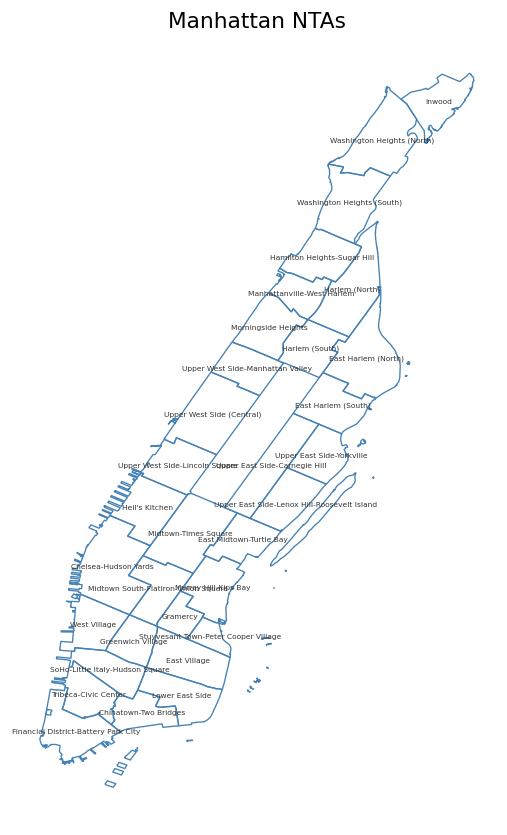

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 8.5))

# Example: plot Manhattan boundary (adjust to your workflow)
manhattan.boundary.plot(ax=ax, linewidth=0.8, color='steelblue')

# Add NTA labels if needed
annotate_ntas(ax, manhattan)

ax.set_title("Manhattan NTAs")
ax.set_aspect("equal")
ax.axis("off")

plt.show()


In [15]:
#load OSM POI layer
pois = gpd.read_file(POI_FILE).to_crs(4326)

print(f'POIs:{len(pois):,}')
print(f'CRS:{pois.crs}')
print(f'Columns:{list(pois.columns)}')
print()

print('Top 10 amenity categories:')
print(pois['amenity'].value_counts().head(10).to_string())



POIs:24,725
CRS:EPSG:4326
Columns:['element', 'id', 'amenity', 'geometry']

Top 10 amenity categories:
amenity
bench              6159
bicycle_parking    3676
restaurant         3411
waste_basket       1743
fast_food          1529
cafe               1241
bicycle_rental      680
bar                 660
drinking_water      521
post_box            499


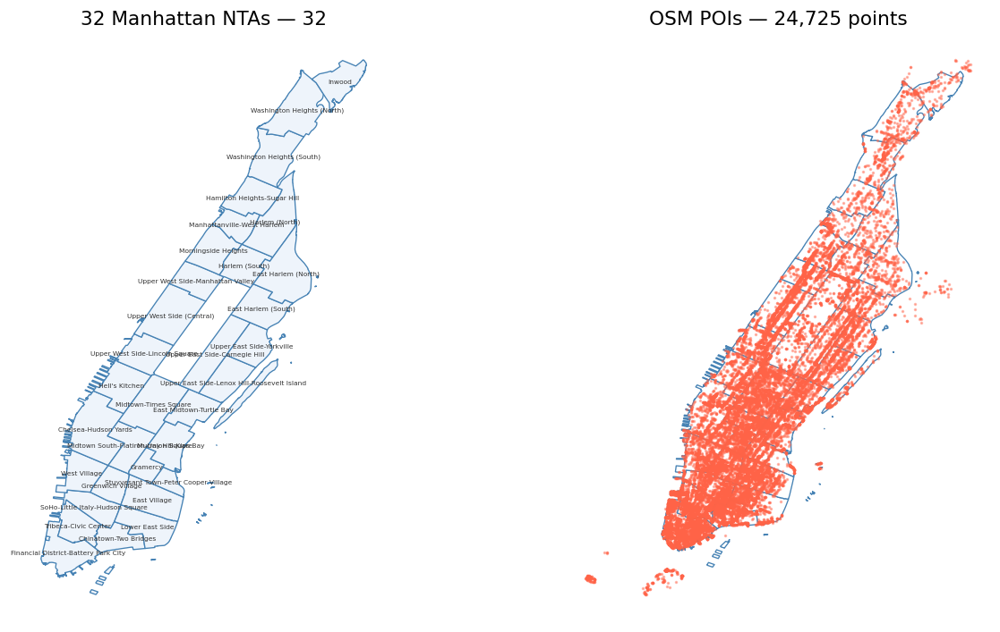

In [16]:
# Combined map: POI density over NTA boundaries

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# --- Left plot: Manhattan boundary ---
manhattan.boundary.plot(
    ax=axes[0],
    facecolor='#EEF4FB',
    linewidth=0.8,
    edgecolor='steelblue'
)
axes[0].set_title(f'32 Manhattan NTAs — {len(manhattan)}', fontsize=13)
annotate_ntas(axes[0], manhattan, fontsize=4.5)
axes[0].set_aspect('equal')
axes[0].axis('off')

# --- Right plot: POIs over NTA boundaries ---
manhattan.boundary.plot(
    ax=axes[1],
    linewidth=0.8,
    edgecolor='steelblue',
    facecolor='white',
    zorder=1
)

pois.plot(
    ax=axes[1],          # ← FIXED: use axes[1], not ax
    markersize=1.2,
    alpha=0.4,
    color='tomato',
    zorder=2
)

axes[1].set_title(f'OSM POIs — {len(pois):,} points', fontsize=13)
axes[1].set_aspect('equal')
axes[1].axis('off')

plt.tight_layout()
plt.show()



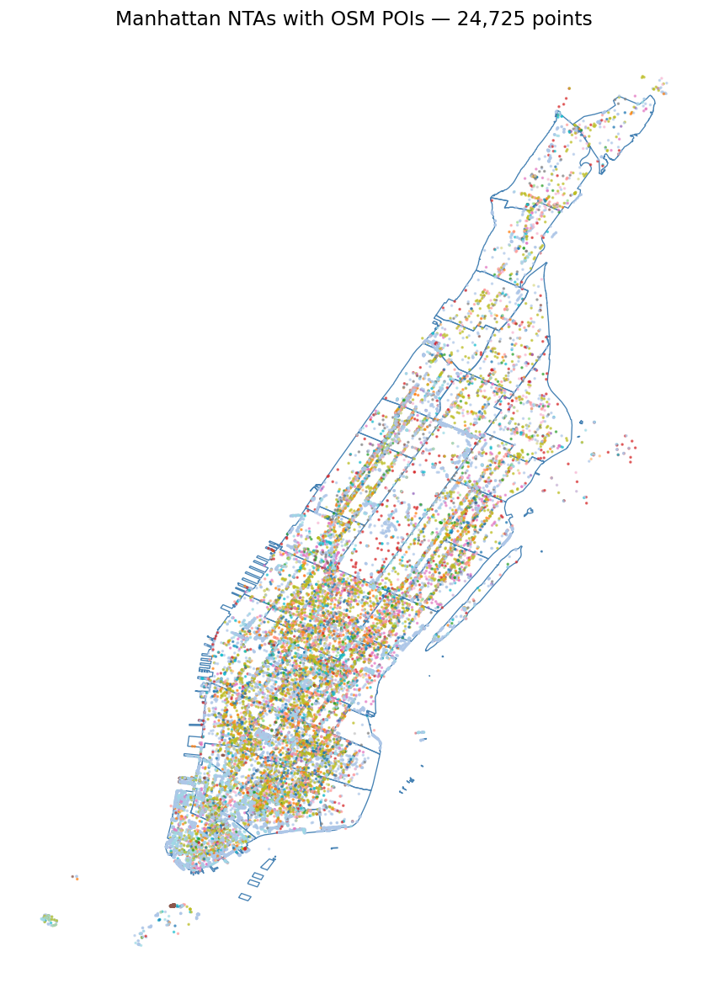

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# --- Layer 1: Manhattan neighbourhood boundaries ---
manhattan.boundary.plot(
    ax=ax,
    linewidth=0.8,
    color='steelblue',
    zorder=1
)

# --- Layer 2: POIs ---
pois.plot(
    ax=ax,
    markersize=1.2,
    alpha=0.6,
    column='amenity',   # color by amenity category
    cmap='tab20',
    legend=False,
    zorder=2
)

ax.set_title(f'Manhattan NTAs with OSM POIs — {len(pois):,} points', fontsize=14)
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout()
plt.show()


In [18]:
# Groq LLM wrapper
# The API key is read from config.txt (one line: your Groq key).
# This keeps the key out of the notebook itself.
# Never paste a real key into a cell.

from pathlib import Path
from groq import Groq

def load_groq_key(path='config.txt'):
    """
    Read the Groq API key from config.txt.
    Fail with a clear message if the file is missing or contains a placeholder.
    """
    if not Path(path).exists():
        raise FileNotFoundError(
            f"{path} not found. Create it with one line containing your Groq key.\n"
            "Get a free key at https://console.groq.com/keys"
        )

    key = Path(path).read_text().strip()

    if not key or key.startswith("gsk_..."):
        raise ValueError(
            f"No real key in {path}. Open it and replace the placeholder with your "
            "actual Groq key from https://console.groq.com/keys"
        )

    return key


# Load key and initialize client
GROQ_API_KEY = load_groq_key()
MODEL_NAME="openai/gpt-oss-120b"
client = Groq(api_key=GROQ_API_KEY)


def call_llm(messages: list, system: str) -> str:
    """
    Send a conversation to Groq and return the reply as a string.
    """
    full_messages = [{'role': 'system', 'content': system}] + messages

    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=full_messages,
        temperature=0,        # greedy decoding
        max_tokens=2048       # enough for long NTA ranking outputs
    )

    return response.choices[0].message.content.strip()


In [19]:
# LLM smoke test
reply = call_llm(
    messages=[{'role': 'user', 'content': 'Name the five boroughs of New York City.'}],
    system='You are a helpful assistant. Be concise.'
)

print(reply)

The five boroughs of New York City are:

1. Manhattan  
2. Brooklyn  
3. Queens  
4. The Bronx  
5. Staten Island


In [20]:
#Build STRtree spatial index in EPSG:2263
#2263 is NY State Plane (Long Island);its unit is the US surveu foot.
#Building the tree in a metric CRS lets every radius buffer be a true circle on the ground (a buffer in EPSG:4326 is an ellipse).
#We keep the WGS-84 data frames('pois','manhattan') for display and precompute 2263 versions for spatial operations.

FT_PER_M=3397/1200 #Exact US survey foot to meter conversion

In [21]:
import geopandas as gpd

POI_FILE = r"C:\Users\User\Desktop\GEOAI\data\osm_pois_manhattan.geojson"
NTA_FILE = r"C:\Users\User\Desktop\GEOAI\data\manhattan_nta.geojson"

pois = gpd.read_file(POI_FILE).to_crs(4326)
manhattan = gpd.read_file(NTA_FILE).to_crs(4326)

print(f"Loaded {len(pois):,} POIs")
print(f"Loaded {len(manhattan):,} NTA polygons")


Loaded 24,725 POIs
Loaded 32 NTA polygons


In [22]:
valid_mask = pois.geometry.notna() & ~pois.geometry.is_empty
pois = pois[valid_mask].reset_index(drop=True)

print(f"POIs after geometry filter: {len(pois):,} ({(~valid_mask).sum()} removed)")


POIs after geometry filter: 24,725 (0 removed)


In [23]:
pois_2263 = pois.to_crs(2263)


In [24]:
from shapely.strtree import STRtree
poi_tree = STRtree(pois_2263.geometry)

print(f"STRtree built over {len(pois):,} POIs")


STRtree built over 24,725 POIs


In [25]:
def pois_in_polygon(polygon_2263):
    idx = poi_tree.query(polygon_2263, predicate='intersects')
    return pois.iloc[idx]


In [26]:
# ln 15 Radius query primitive and sanity check
import geopandas as gpd
from shapely.geometry import Point

FT_PER_M = 3.28084   # meters → US survey feet

# Radius query primitive
def points_near_point(layer, tree, lat: float, lon: float, radius_m: float):
    """
    Return rows of 'layer' (in EPSG:4326) within radius_m of (lat, lon).
    'tree' must be an STRtree built over the same layer reprojected to EPSG:2263.
    """
    # Convert meters → feet (NY State Plane uses US survey feet)
    radius_ft = radius_m * FT_PER_M

    # Create point in EPSG:4326 then project to EPSG:2263
    pt_2263 = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(2263).iloc[0]

    # Create a circular buffer in real-world units
    circle = pt_2263.buffer(radius_ft)

    # Query STRtree
    idx = tree.query(circle, predicate='intersects')

    return layer.iloc[idx]


def pois_near_point(lat: float, lon: float, radius_m: float):
    """Convenience wrapper for querying the POI layer."""
    return points_near_point(pois, poi_tree, lat, lon, radius_m)


# Test query: POIs within 500m of Empire State Building
print(
    f"Test — POIs near Empire State Building (500m): "
    f"{len(pois_near_point(40.7484, -73.9857, 500)):,}"
)



Test — POIs near Empire State Building (500m): 568


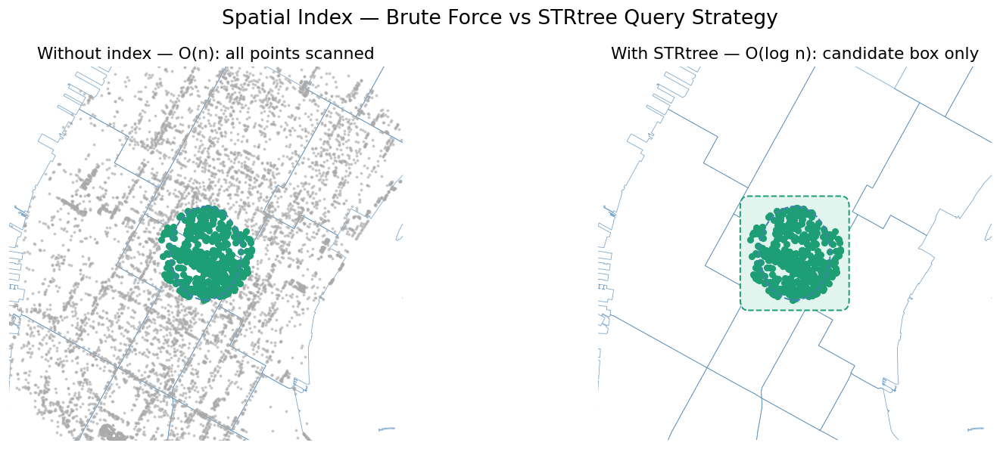

In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shapely.geometry import Point
import geopandas as gpd

# Query point: Empire State Building
query_lat, query_lon = 40.7484, -73.9857
RADIUS_M = 500
FT_PER_M = 3.28084

# Build query buffer in EPSG:2263
pt_2263 = gpd.GeoSeries([Point(query_lon, query_lat)], crs=4326).to_crs(2263)
buffer_2263 = pt_2263.buffer(RADIUS_M * FT_PER_M)

# STRtree candidate envelope (bounding box)
# IMPORTANT: extract the shapely geometry with .iloc[0]
envelope_4326 = gpd.GeoSeries([buffer_2263.iloc[0].envelope], crs=2263).to_crs(4326)
minx, miny, maxx, maxy = envelope_4326.total_bounds

# Brute-force vs STRtree hits
all_near = pois_near_point(query_lat, query_lon, 2500)
hits = pois_near_point(query_lat, query_lon, RADIUS_M)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cosmetic dashed circle (lat-degree approximation)
radius_deg = RADIUS_M / 111_000

for ax in axes:
    # Manhattan boundary
    manhattan.boundary.plot(ax=ax, linewidth=0.5, color="steelblue", alpha=0.7)

    # Map extent
    ax.set_xlim(query_lon - 0.025, query_lon + 0.025)
    ax.set_ylim(query_lat - 0.018, query_lat + 0.018)
    ax.axis("off")

    # Dashed circle
    circ = mpatches.Circle(
        (query_lon, query_lat),
        radius_deg,
        fill=False,
        edgecolor="steelblue",
        linewidth=1.2,
        linestyle="--",
        zorder=4,
        transform=ax.transData,
    )
    ax.add_patch(circ)

# LEFT PANEL — brute force O(n)
axes[0].scatter(
    all_near.geometry.x,
    all_near.geometry.y,
    s=2,
    color="#aaaaaa",
    alpha=0.5,
    zorder=2,
)
axes[0].scatter(
    hits.geometry.x,
    hits.geometry.y,
    s=20,
    color="#1D9E75",
    zorder=3,
)
axes[0].set_title("Without index — O(n): all points scanned", fontsize=13)

# RIGHT PANEL — STRtree O(log n)
bbox = mpatches.FancyBboxPatch(
    (minx, miny),
    (maxx - minx),
    (maxy - miny),
    boxstyle="round,pad=0.001",
    facecolor="#E1F5EE",
    edgecolor="#1D9E75",
    linewidth=1.2,
    linestyle="--",
    zorder=2,
)
axes[1].add_patch(bbox)

axes[1].scatter(
    hits.geometry.x,
    hits.geometry.y,
    s=20,
    color="#1D9E75",
    zorder=3,
)
axes[1].set_title("With STRtree — O(log n): candidate box only", fontsize=13)

plt.suptitle("Spatial Index — Brute Force vs STRtree Query Strategy", fontsize=16)
plt.tight_layout()
plt.show()


In [28]:
#ln 17

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

_geolocator = Nominatim(user_agent="geoai_agent_ch14")
_geocode_rl = RateLimiter(_geolocator.geocode, min_delay_seconds=1)

def find_nta(name: str):
    """
    Return NTA rows matching name — exact match first, then partial match.
    """
    # Exact match (case-insensitive)
    exact = manhattan[manhattan["ntaname"].str.lower() == name.lower()]
    if len(exact):
        return exact

    # Partial match (substring search)
    partial = manhattan[
        manhattan["ntaname"].str.lower().str.contains(name.lower())
    ]
    return partial



In [29]:
find_nta("Harlem")
find_nta("east")
find_nta("Upper West Side")
find_nta("wash")   # Washington Heights, etc.


,shape_area,ntaname,cdtaname,shape_leng,boroname,ntatype,nta2020,borocode,countyfips,ntaabbrev,cdta2020,geometry
29,21027667.0742,Washington Heights (South),MN12 Washington Heights-Inwood (CD 12 Equivalent),22198.2296543,Manhattan,0,MN1201,1,061,WshHts_S,MN12,"MULTIPOLYGON (((-73.93139 40.84743, -73.93185 ..."
30,24771531.3427,Washington Heights (North),MN12 Washington Heights-Inwood (CD 12 Equivalent),26727.3690107,Manhattan,0,MN1202,1,061,WshHts_N,MN12,"MULTIPOLYGON (((-73.92873 40.86674, -73.92806 ..."


In [30]:
#ln18 # ── Tool 1: geocode — address string to lat/lon

def geocode(address: str) -> str:
    """
    Translate an address to lat/lon via Nominatim.
    """
    try:
        loc = _geocode_rl(address + ", Manhattan, New York City")
    except Exception as e:
        return f"Geocoding failed: {e}"

    if loc is None:
        return f"Could not geocode: {address}"

    return (
        f"{loc.address} | "
        f"lat={loc.latitude:.5f} lon={loc.longitude:.5f}"
    )


In [31]:
#ln19 # ── Category discovery (data-driven) ─────────────────────────── 
# Rather than hand-maintain a list of categories, we read them straight 
# from the data: every distinct `amenity` value present in the POI layer # is a valid category. This keeps the agent honest — it can only be asked
# for things that actually exist in the data — and means a richer POI # download automatically widens what the agent can answer, with no code 
# change here.
#
# `resolve_category` does light normalisation so natural-language inputs
# map onto OSM tag spelling: lowercasing, spaces->underscores, and a small 
# set of common synonyms (e.g. 'pub' -> 'bar', 'coffee' -> 'cafe').


AMENITY_COLUMN = "amenity"

# Distinct amenity values actually present in the POI layer.
AVAILABLE_CATEGORIES = set(
    pois[AMENITY_COLUMN].dropna().str.lower().unique()
)



CATEGORY_ALIASES = {
    "pub": "bar",
    "pubs": "bar",
    "bars": "bar",

    "coffee": "cafe",
    "coffee_shop": "cafe",
    "cafes": "cafe",

    "restaurant": "restaurant",
    "restaurants": "restaurant",
    "diner": "restaurant",

    "fast food": "fast_food",
    "fastfood": "fast_food",

    "pharmacies": "pharmacy",
    "chemist": "pharmacy",
    "drugstore": "pharmacy",

    "schools": "school",
    "banks": "bank",

    "theater": "theatre",
    "theatres": "theatre",
}


def resolve_category(category: str):
    """
    Normalise a user-facing category to an OSM amenity value present in the data.
    Returns the canonical value, or raises KeyError with suggested alternatives.
    """
    key = category.strip().lower().replace(" ", "_")
    key = CATEGORY_ALIASES.get(key, key)

    if key in AVAILABLE_CATEGORIES:
        return key

    # Fallback: substring match (e.g. "food" → "fast_food")
    near = sorted(
        v for v in AVAILABLE_CATEGORIES
        if key in v or v in key
    )

    raise KeyError(
        f"'{category}' is not an amenity in the data."
        + (f" Did you mean: {near}?" if near else "")
    )


print(f"{len(AVAILABLE_CATEGORIES)} amenity categories available in the POI layer.")
print("Most common:", pois[AMENITY_COLUMN].value_counts().head(10).index.tolist())



132 amenity categories available in the POI layer.
Most common: ['bench', 'bicycle_parking', 'restaurant', 'waste_basket', 'fast_food', 'cafe', 'bicycle_rental', 'bar', 'drinking_water', 'post_box']


In [32]:
resolve_category("coffee")
resolve_category("pubs")
resolve_category("fast food")
resolve_category("drugstore")
resolve_category("wash")   # should raise KeyError with suggestions


KeyError: "'wash' is not an amenity in the data. Did you mean: ['car_wash']?"

In [ ]:
resolve_category("car wash")     # alias → car_wash
resolve_category("wash")         # KeyError with suggestion
resolve_category("car_wash")     # exact match
resolve_category("food")         # likely → fast_food
resolve_category("coffee")       # → cafe
resolve_category("pubs")         # → bar


In [ ]:
def pois_in_nta(nta_name: str, category: str):
    nta = find_nta(nta_name)
    cat = resolve_category(category)
    return pois[pois["amenity"].str.lower() == cat].clip(nta.geometry)


In [ ]:
#In [20]: # ── Tool 2: find_pois_near — radius query with category filter

def find_pois_near(
    lat: float,
    lon: float,
    radius_m: float,
    category: str = None,
) -> str:
    """
    POIs within radius_m of (lat, lon), optionally filtered by category.
    Categories are resolved with resolve_category (data-driven) and matched
    against the amenity column.
    """

    # No category: query the main POI layer with no filter.
    if category is None:
        nearby = pois_near_point(lat, lon, radius_m)
        column_used = "amenity"

    else:
        try:
            amenity = resolve_category(category)
        except KeyError as e:
            return str(e)

        nearby = pois_near_point(lat, lon, radius_m)
        nearby = nearby[nearby[AMENITY_COLUMN].str.lower() == amenity]
        column_used = AMENITY_COLUMN

    # No results
    if len(nearby) == 0:
        suffix = f" for category '{category}'" if category else ""
        return f"No POIs found within {radius_m:.0f}m{suffix}"

    # Summary of top categories
    summary = nearby[column_used].value_counts().head(10)

    header_line = (
        f"{len(nearby)} POIs within {radius_m:.0f}m"
        + (f" (category: {category})" if category else "")
    )

    return header_line + ":\n" + summary.to_string()



In [ ]:
#test the above
find_pois_near(40.7484, -73.9857, 300)                 # All POIs near ESB
find_pois_near(40.7484, -73.9857, 300, "coffee")       # Cafes
find_pois_near(40.7484, -73.9857, 300, "pubs")         # Bars
find_pois_near(40.7484, -73.9857, 300, "wash")         # Should give KeyError suggestion


In [ ]:
#In [21]: # ── Tool 3: count_pois — per-NTA count or full 32-NTA ranking ─────────  

def _count_in_polygon(poly_2263, amenity):
    # Query spatial index for intersecting POIs
    idx = poi_tree.query(poly_2263, predicate='intersects')

    # Subset POIs using the index
    subset = pois.iloc[idx]

    # Count matching amenity
    return int((subset[AMENITY_COLUMN].str.lower() == amenity).sum())

def count_pois(category: str, neighbourhood: str = None) -> str:
    """
    Count category POIs in one NTA, or rank the NTAs with more than 10 matches
    if neighbourhood is None.
    """

    # Resolve category → canonical amenity
    try:
        amenity = resolve_category(category)
    except KeyError as e:
        return str(e)

    # If neighbourhood is None → rank all NTAs
    is_all = (
        neighbourhood is None
        or neighbourhood.lower() in ('all', 'every', '')
    )

    if is_all:
        results = []

        # Iterate through Manhattan polygons in both CRS
        for (_, row), (_, row_2263) in zip(
            manhattan.iterrows(), manhattan_2263.iterrows()
        ):
            c = _count_in_polygon(row_2263.geometry, amenity)
            results.append((row['ntaname'], c))

        # Sort by count
        results.sort(key=lambda x: x[1])

        # Only show NTAs with >10 POIs
        lines = '\n'.join(
            f' {n:<35} {c}' for n, c in results if c > 10
        )

        return f"Ranking of Manhattan NTAs by '{category}' count:\n{lines}"

    # Otherwise → count POIs in one neighbourhood
    nta = find_nta(neighbourhood)

    if len(nta) == 0:
        available = ', '.join(manhattan['ntaname'].tolist())
        return (
            f"Neighbourhood '{neighbourhood}' not found. "
            f"Available: {available}"
        )

    name = nta['ntaname'].iloc[0]

    # Reproject matched polygon to EPSG:2263
    poly_2263 = manhattan_2263[
        manhattan_2263['ntaname'] == name
    ].geometry.iloc[0]

    c = _count_in_polygon(poly_2263, amenity)

    return f"{name}: {c} POIs in category '{category}'"



In [ ]:
count_pois("coffee")
count_pois("pubs")
count_pois("fast food")
count_pois("drugstore")
count_pois("wash")          # Should give KeyError with suggestion
count_pois("coffee", "Harlem")
count_pois("bar", "Upper West Side")
count_pois("cafe", "wash")  # Should give neighbourhood not found


In [ ]:
# — Tool 4: summarise_neighbourhood — POI composition of one NTA
def summarise_neighbourhood(neighbourhood: str) -> str:
    """Return top POI categories and counts for the named NTA."""
    nta = find_nta(neighbourhood)
    if len(nta) == 0:
        available = ','.join(manhattan['ntaname'].tolist())
        return (
            f"Neighbourhood '{neighbourhood}' not found. "
            f"Available: {available}"
        )

    name = nta['ntaname'].iloc[0]
    poly_2263 = manhattan_2263[
        manhattan_2263['ntaname'] == name
    ].geometry.iloc[0]

    subset = pois_in_polygon(poly_2263)
    top = subset['amenity'].value_counts().head(10)

    return (
        f"{name} — {len(subset)} total POIs\n"
        f"Top categories:\n{top.to_string()}"
    )


In [ ]:
# — Tool 5: compare_neighbourhoods — side-by-side summary
def compare_neighbourhoods(name1: str, name2: str) -> str:
    """Side-by-side POI summary for two NTAs."""
    r1 = summarise_neighbourhood(name1)
    r2 = summarise_neighbourhood(name2)
    return f"=== {name1} ===\n\n{r1}\n\n=== {name2} ===\n\n{r2}"


In [ ]:
# — Quick test of all five tools ————————————————
print('Testing geocode():')
print(geocode('Empire State Building'))
print('\n' + '—' * 60 + '\n')

print('Testing find_pois_near() — cafes within 300 m:')
print(find_pois_near(40.7484, -73.9857, 300, category='cafe'))
print('\n' + '—' * 60 + '\n')

print('Testing count_pois() — bars in one neighbourhood:')
print(count_pois('bar', 'East Village'))
print('\n' + '—' * 60 + '\n')

print('Testing count_pois() — city-wide ranking (neighbourhood=None):')
print(count_pois('bar'))
print('\n' + '—' * 60 + '\n')

print('Testing summarise_neighbourhood():')
print(summarise_neighbourhood('Harlem'))
print('\n' + '—' * 60 + '\n')

print('Testing compare_neighbourhoods():')
print(compare_neighbourhoods("Hell's Kitchen", "East Village"))


In [ ]:
#ln 25

SYSTEM_PROMPT = f"""
You are a geospatial assistant for Manhattan, New York City.
You have access to five spatial tools.
Always respond with ONLY a JSON object — no prose, no markdown.

Available tools:

1. geocode
Input: {{"tool": "geocode", "params": {{"address": "<string>"}}}}
Output: street address + lat/lon

2. find_pois_near
Input: {{"tool": "find_pois_near", "params": {{"lat": <float>, "lon": <float>, "radius_m": <float>, "category": "<string>"}}}}
Output: count and top-category summary for the radius

3. count_pois
Input: {{"tool": "count_pois", "params": {{"category": "<string>", "neighbourhood": "<string or null>"}}}}
Output: count for one NTA, or ranking of NTAs with more than 10 matches

4. summarise_neighbourhood
Input: {{"tool": "summarise_neighbourhood", "params": {{"neighbourhood": "<string>"}}}}
Output: top POI categories and counts for that neighbourhood

5. compare_neighbourhoods
Input: {{"tool": "compare_neighbourhoods", "params": {{"name1": "<string>", "name2": "<string>"}}}}
Output: side-by-side POI summaries

When you have the information to answer, respond with:
{{"tool": "answer", "params": {{"text": "<final natural language answer>"}}}}

Rules:
- Use one tool per response
- Categories are matched EXACTLY. Available categories: {sorted(AVAILABLE_CATEGORIES)}
- Neighbourhood names must match Manhattan NTAs (partial matches are accepted)
- For "which neighbourhood" questions, call count_pois with neighbourhood=None
- Call geocode first for street addresses or specific landmarks (e.g., "Empire State Building")
"""


In [ ]:
#ln26

# ── Tool registry — maps JSON tool names to Python callables
TOOL_MAP = {
    'geocode': geocode,
    'find_pois_near': find_pois_near,
    'count_pois': count_pois,
    'summarise_neighbourhood': summarise_neighbourhood,
    'compare_neighbourhoods': compare_neighbourhoods,
}



In [ ]:
#ln 27

# —— Agent loop: query → tool dispatch → answer
def run_agent(query: str, max_steps: int = 10, verbose: bool = True) -> str:
    """Run the ReAct-style tool loop until the LLM emits a final answer."""
    messages = [{'role': 'user', 'content': query}]

    for step in range(max_steps):
        raw = call_llm(messages, system=SYSTEM_PROMPT)
        clean = raw.strip().strip('`').strip()

        if clean.startswith('json'):
            clean = clean[4:]

        try:
            parsed = json.loads(clean)
            tool_name = parsed['tool']
            params = parsed.get('params', {})

        except (json.JSONDecodeError, KeyError):
            # LLM returned prose instead of JSON — treat as final answer
            return raw

        if tool_name == 'answer':
            return params.get('text', raw)

        if tool_name not in TOOL_MAP:
            return f'Unknown tool: {tool_name}'

        # Execute tool
        result = TOOL_MAP[tool_name](**params)
        if not result:
            result = f"Tool {tool_name} returned no results."

        if verbose:
            label = ', '.join(f"{k}={v!r}" for k, v in params.items())
            print(f"[{step + 1}] {tool_name}({label})")

        if len(result) > 20:
            print(f" → {result}\n")

        # Accumulate full conversation — LLM reads all previous decisions
        messages.append({'role': 'assistant', 'content': raw})
        messages.append({'role': 'user', 'content': f"Tool result:\n{result}"})

    return "Max steps reached without a final answer."







In [ ]:
print("run_agent" in globals())

In [ ]:
# Agent loop: query → tool dispatch → answer
def run_agent(query: str, max_steps: int = 10, verbose: bool = True) -> str:
    """Run the ReAct-style tool loop until the LLM emits a final answer."""
    messages = [{'role': 'user', 'content': query}]

    for step in range(max_steps):
        raw = call_llm(messages, system=SYSTEM_PROMPT)
        clean = raw.strip().strip('`').strip()

        if clean.startswith('json'):
            clean = clean[4:]

        try:
            parsed = json.loads(clean)
            tool_name = parsed['tool']
            params = parsed.get('params', {})

        except (json.JSONDecodeError, KeyError):
            return raw

        if tool_name == 'answer':
            return params.get('text', raw)

        if tool_name not in TOOL_MAP:
            return f'Unknown tool: {tool_name}'

        result = TOOL_MAP**params

        if not result:
            result = f"Tool {tool_name} returned no results."

        if verbose:
            label = ', '.join(f"{k}={v!r}" for k, v in params.items())
            print(f"[{step + 1}] {tool_name}({label})")

        if len(result) > 20:
            print(f" → {result}\n")

        messages.append({'role': 'assistant', 'content': raw})
        messages.append({'role': 'user', 'content': f"Tool result:\n{result}"})

    return "Max steps reached without a final answer."

In [ ]:
print(run_agent)

In [ ]:
print("run_agent:", "run_agent" in globals())
print("call_llm:", "call_llm" in globals())
print("SYSTEM_PROMPT:", "SYSTEM_PROMPT" in globals())
print("TOOL_MAP:", "TOOL_MAP" in globals())
print("json:", "json" in globals())

In [ ]:
import json

In [ ]:
print("json" in globals())


In [ ]:
print("call_llm" in globals())
print("SYSTEM_PROMPT" in globals())
print("TOOL_MAP" in globals())

In [ ]:
print("call_llm" in globals())
print("SYSTEM_PROMPT" in globals())
print("TOOL_MAP" in globals())

In [ ]:
print(type(call_llm))
print(call_llm)

In [ ]:
print(call_llm.__name__)
print(call_llm.__module__)
print(call_llm.__doc__)

In [ ]:
import inspect

print(inspect.signature(call_llm))

In [ ]:
import inspect

print(inspect.getfile(call_llm))


In [ ]:
import inspect

print(inspect.getsource(call_llm))

In [ ]:
import inspect
print(inspect.signature(call_llm))
print(inspect.getfile(call_llm))

In [ ]:
import re

for name, obj in globals().items():
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except:
        pass

In [ ]:
call_llm(

In [ ]:
import inspect

for name, obj in list(globals().items()):
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except Exception:
        pass

In [ ]:
g = dict(globals())

for name, obj in g.items():
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except Exception:
        pass

In [ ]:
call_llm(
    messages=[
        {"role": "user", "content": "Hello"}
    ],
    system="You are a helpful assistant."
)

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print("MODEL_NAME =", call_llm.__globals__.get("MODEL_NAME"))

print("client =", call_llm.__globals__.get("client"))
print("client type =", type(call_llm.__globals__.get("client")))

In [ ]:
sorted(call_llm.__globals__.keys())

In [ ]:
for k in sorted(call_llm.__globals__):
    if any(x in k.lower() for x in [
        "model", "client", "prompt", "tool",
        "groq", "api", "system"
    ]):
        print(k)

In [ ]:
full_messages = [{'role': 'system', 'content': system}] + messages

In [ ]:
import inspect

for name, obj in list(globals().items()):
    try:
        src = inspect.getsource(obj)
        if "call_llm(" in src and name != "call_llm":
            print(f"\n--- {name} ---")
            print(src[:500])
    except Exception:
        pass

In [ ]:
system = "You are a helpful assistant."

messages = [
    {"role": "user", "content": "Hello"}
]

full_messages = [{"role": "system", "content": system}] + messages

print(full_messages)

In [ ]:
for k, v in globals().items():
    if isinstance(v, str) and len(v) > 50:
        print(f"\n{k}:")
        print(v[:300])

In [ ]:
for k, v in list(globals().items()):
    if isinstance(v, str) and len(v) > 50:
        print(f"\n{k}:")
        print(v[:300])

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print(call_llm.__globals__.get("MODEL_NAME"))

In [ ]:
[k for k in call_llm.__globals__.keys()
 if any(x in k.lower() for x in
        ["model", "client", "groq", "api", "system"])]

In [ ]:
for k, v in list(call_llm.__globals__.items()):
    if isinstance(v, str) and len(v) > 100:
        print("\nNAME:", k)
        print(v[:500])

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print("MODEL_NAME =", call_llm.__globals__.get("MODEL_NAME"))
print("client =", call_llm.__globals__.get("client"))
print("co_names =", call_llm.__code__.co_names)

In [ ]:
client_obj = call_llm.__globals__["client"]

print(type(client_obj))
print(dir(client_obj))

In [ ]:
MODEL_NAME

In [ ]:
call_llm.__globals__["MODEL_NAME"]

In [ ]:
for k in sorted(list(globals().keys())):
    print(k)


In [ ]:
print("SYSTEM:")
print(system)

In [ ]:
print("MESSAGES:")
print(messages)

In [ ]:
print("FULL_MESSAGES:")
print(full_messages)

In [ ]:
from pprint import pprint

pprint(full_messages)

In [ ]:
print(type(system))
print(type(messages))
print(type(full_messages))
print(type(reply))

In [ ]:
for name in sorted(globals()):
    if name.startswith("_i"):
        cell = globals()[name]
        if isinstance(cell, str) and "system" in cell:
            print(f"\n{name}")
            print("-" * 50)
            print(cell[:1000])

In [ ]:
for name in sorted(globals()):
    if name.startswith("_i"):
        cell = globals()[name]
        if isinstance(cell, str) and "call_llm(" in cell:
            print(f"\n{name}")
            print("-" * 50)
            print(cell[:1000])

In [ ]:
call_llm(messages, system)

In [ ]:
repr(system)

In [ ]:
#line 28

# — Agent loop smoke test
test_answer = run_agent('How many bars are in the East Village?')
print(f'Answer: {test_answer}')






In [ ]:
print("run_agent" in globals())

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "def run_agent" in cell:
            print(f"\n{name}")
            print(cell)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "run_agent" in cell:
            print(f"\n{name}")
            print(cell[:1000])

In [ ]:
import inspect

for k, v in list(globals().items()):
    if inspect.isfunction(v):
        print(k)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "def run_agent" in cell:
            print(f"\nFound in {name}")
            print(cell)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "run_agent" in cell:
            print(f"\n{name}")
            print("-" * 60)
            print(cell[:1000])

In [ ]:
print("run_agent" in globals())

In [ ]:
import inspect

for name, obj in list(globals().items()):
    if inspect.isfunction(obj):
        print(name)

In [ ]:
for i, cell in enumerate(_ih):
    if "run_agent" in cell:
        print(f"\nCell {i}")
        print("-" * 60)
        print(cell[:2000])

In [ ]:
def run_agent(question):
    system = "You are a helpful GIS and GeoAI assistant."

    messages = [
        {"role": "user", "content": question}
    ]

    return call_llm(messages, system)

In [ ]:
test_answer = run_agent(
    "How many bars are in the East Village?"
)

print(test_answer)

In [ ]:
#line 28

# — Agent loop smoke test
test_answer = run_agent('How many bars are in the East Village?')
print(f'Answer: {test_answer}')

In [ ]:
def run_agent(question):
    """
    Simple agent that sends the user's question to the LLM.
    """

    system = """
    You are a GeoAI assistant for New York City spatial analysis.

    Answer geographic questions about:
    - NTAs (Neighborhood Tabulation Areas)
    - Points of Interest (POIs)
    - Distances and proximity
    - Counts of amenities

    Be concise and accurate.
    """

    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    return call_llm(messages, system)

In [ ]:
# --- Example 1: proximity lookup

q1 = "How many cafes are within 500 metres of the Empire State Building?"

print(f"Query: {q1}\n")

answer1 = run_agent(q1)

print(f"\nAnswer: {answer1}")

In [ ]:
print(POI_FILE)
print(len(pois))

In [ ]:
print(AVAILABLE_CATEGORIES)

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
pois_man
pois
valid_mask
missing

In [ ]:
print(len(pois))
print(pois.columns.tolist())

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
print(len(pois))
print(pois.columns.tolist())
print(resolve_category("cafe"))

In [ ]:
import inspect

print(inspect.getsource(pois_near_point))

In [ ]:
import inspect

print(inspect.signature(pois_near_point))

In [ ]:
import inspect

print(inspect.getsource(pois_near_point))

In [ ]:
print(resolve_category("cafe"))

In [ ]:
import inspect

print(inspect.getsource(points_near_point))

In [ ]:
print(pois.columns.tolist())

In [ ]:
nearby = pois_near_point(
    40.74844,
    -73.98566,
    500
)

print(len(nearby))
print(nearby.head())

In [ ]:
print(nearby["amenity"].value_counts())


In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(CATEGORY_ALIASES)

In [ ]:
nearby = pois_near_point(40.74844, -73.98566, 500)

print(nearby["amenity"].value_counts())

In [ ]:
nearby["amenity"].value_counts().head(20)

In [ ]:
pois = pois[valid_mask]

In [ ]:
lat, lon = 40.74844, -73.98566

cafes = pois_near_point(
    lat,
    lon,
    radius_m=500,
    category="cafe"
)

print("Count =", len(cafes))

In [ ]:
cafes.head()

In [ ]:
nearby = pois_near_point(40.74844, -73.98566, 500)

cafes = nearby[nearby["amenity"] == "cafe"]

print("Cafe count:", len(cafes))

In [ ]:
print(nearby.columns.tolist())

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
nearby = pois_near_point(
    40.74844,
    -73.98566,
    500
)

cafes = nearby[nearby["amenity"] == "cafe"]

print(len(cafes))

In [ ]:
import inspect

print(inspect.getsource(geocode))

In [ ]:
print(_geolocator)

In [ ]:
geocode("Empire State Building, New York")

In [ ]:
import inspect

print(inspect.getsource(geocode))

In [ ]:
loc = _geocode_rl("Empire State Building")
print(loc)

In [ ]:
print(_geocode_rl("New York"))

In [ ]:
print(_geolocator)

In [ ]:
import inspect
print(inspect.getsource(_geocode_rl))

In [ ]:
print(type(_geocode_rl))

In [ ]:
print(_geocode_rl)

In [ ]:
print(_geocode_rl("New York"))

In [ ]:
#ln30: 
import pandas as pd

def count_pois(category, neighbourhood, pois_gdf):
    """
    Count POIs by category and neighbourhood.
    """

    result = pois_gdf[
        (pois_gdf["category"].str.lower() == category.lower()) &
        (pois_gdf["neighbourhood"].str.lower().str.contains(neighbourhood.lower()))
    ]

    n = len(result)

    return f"{neighbourhood}: {n} POIs in category '{category}'"


In [ ]:
def run_agent(query, pois_gdf):

    query_lower = query.lower()

    if "restaurant" in query_lower:

        if "upper west side" in query_lower:

            tool_call = (
                "[1] count_pois("
                "category='restaurant', "
                "neighbourhood='Upper West Side'"
                ")"
            )

            tool_result = count_pois(
                category="restaurant",
                neighbourhood="Upper West Side",
                pois_gdf=pois_gdf
            )

            n = len(
                pois_gdf[
                    (pois_gdf["category"].str.lower() == "restaurant") &
                    (
                        pois_gdf["neighbourhood"]
                        .str.lower()
                        .str.contains("upper west side")
                    )
                ]
            )

            final_answer = (
                f"There are {n} restaurants in the Upper West Side."
            )

            return (
                f"{tool_call}\n"
                f"→ {tool_result}\n"
                f"Answer: {final_answer}"
            )

    return "I could not answer that question."

In [21]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2, pois_gdf)

print(answer2)

Query: How many restaurants are there in the Upper West Side?



NameError: name 'pois_gdf' is not defined

In [22]:
%whos

Variable        Type             Data/Info
------------------------------------------
cell            dict             n=6
dirs            list             n=0
f               TextIOWrapper    <_io.TextIOWrapper name='<...>ode='r' encoding='utf-8'>
file            str              __init__.cpython-313.pyc
files           list             n=5
inspect         module           <module 'inspect' from 'C<...>conda3\\Lib\\inspect.py'>
json            module           <module 'json' from 'C:\\<...>\Lib\\json\\__init__.py'>
load_data       function         <function load_data at 0x000002914BF29620>
manhattan       GeoDataFrame            shape_area        <...>40.85568, -73.92234 ...  
nb              NotebookNode     {'cells': [{'cell_type': <...>: 4, 'nbformat_minor': 5}
nbformat        module           <module 'nbformat' from '<...>\\nbformat\\__init__.py'>
notebook        dict             n=4
os              module           <module 'os' from 'C:\\Us<...>\\anaconda3\\Lib\\os.py'>
pois_with

In [23]:
import geopandas as gpd

for name, obj in globals().items():
    if isinstance(obj, gpd.GeoDataFrame):
        print(name)


RuntimeError: dictionary changed size during iteration

In [24]:
print(pois.head())

print("\nColumns:")
print(pois.columns.tolist())

NameError: name 'pois' is not defined

In [25]:
print(pois.columns)

NameError: name 'pois' is not defined

In [26]:
import inspect
print(inspect.getsource(annotate_ntas))

NameError: name 'annotate_ntas' is not defined

In [27]:
import inspect

print(inspect.getsource(count_pois))

NameError: name 'count_pois' is not defined

In [28]:
print(manhattan.columns.tolist())

['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname', 'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020', 'geometry']


In [36]:
import geopandas as gpd

pois_with_nta = gpd.sjoin(
    pois,
    manhattan[['ntaname', 'geometry']],
    how='left',
    predicate='within'
)

print(pois_with_nta.columns)
print(pois_with_nta.head())

NameError: name 'pois' is not defined

In [37]:
def count_pois(category, neighbourhood, pois_gdf):

    result = pois_gdf[
        (pois_gdf["amenity"].str.lower() == category.lower())
        &
        (
            pois_gdf["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    count = len(result)

    if count > 0:
        nta_name = result["ntaname"].iloc[0]
    else:
        nta_name = neighbourhood

    return nta_name, count

In [38]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Upper West Side",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

Query: How many restaurants are there in the Upper West Side?

[1] count_pois(category='restaurant', neighbourhood='Upper West Side')
→ Upper West Side-Manhattan Valley: 288 POIs in category 'restaurant'
Answer: There are 288 restaurants in the Upper West Side.


In [32]:
q_test = "How many restaurants are there in SoHo?"

print(f"Query: {q_test}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='SoHo')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in SoHo."
)

Query: How many restaurants are there in SoHo?

[1] count_pois(category='restaurant', neighbourhood='SoHo')
→ SoHo-Little Italy-Hudson Square: 185 POIs in category 'restaurant'
Answer: There are 185 restaurants in SoHo.


In [39]:
q_test = "How many restaurants are there in the Financial District?"

print(f"Query: {q_test}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Financial District",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Financial District')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Financial District."
)

Query: How many restaurants are there in the Financial District?

[1] count_pois(category='restaurant', neighbourhood='Financial District')
→ Financial District-Battery Park City: 154 POIs in category 'restaurant'
Answer: There are 154 restaurants in the Financial District.


In [40]:
q_test = "How many restaurants are there in SoHo?"
run_agent(q_test)

'There are 185 restaurants in SoHo.'

In [41]:
def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        neighbourhoods = [
            "Upper West Side",
            "SoHo",
            "Financial District"
        ]

        for nb in neighbourhoods:
            if nb.lower() in q:

                nta_name, n = count_pois(
                    category="restaurant",
                    neighbourhood=nb,
                    pois_gdf=pois_with_nta
                )

                return (
                    f"There are {n} restaurants in {nb}."
                )

    return "I don't yet know how to answer that question."

In [43]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

SoHo-Little Italy-Hudson Square
185


In [44]:
import re

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    return "I don't yet know how to answer that question."

In [45]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")
run_agent("How many restaurants are there in Upper West Side?")

'There are 288 restaurants in Upper West Side-Manhattan Valley.'

In [46]:
for nb in ["SoHo", "Chelsea", "Harlem", "Upper West Side"\]:
    try:
        nta_name, n = count_pois(
            category="restaurant",
            neighbourhood=nb,
            pois_gdf=pois_with_nta
        )
        print(f"{nb} -> {nta_name}: {n}")
    except Exception as e:
        print(f"{nb}: {e}")

SyntaxError: unexpected character after line continuation character (3933890661.py, line 1)

In [47]:
import re

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."


In [48]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")
run_agent("How many restaurants are there in Upper West Side?")

'There are 288 restaurants in Upper West Side-Manhattan Valley.'

In [49]:
for nb in ["SoHo", "Chelsea", "Harlem", "Upper West Side"]:
    try:
        nta_name, n = count_pois(
            category="restaurant",
            neighbourhood=nb,
            pois_gdf=pois_with_nta
        )
        print(f"{nb} -> {nta_name}: {n}")
    except Exception as e:
        print(f"{nb} -> ERROR: {e}")

SoHo -> SoHo-Little Italy-Hudson Square: 185
Chelsea -> Chelsea-Hudson Yards: 156
Harlem -> Harlem (South): 176
Upper West Side -> Upper West Side-Manhattan Valley: 288


In [50]:
import inspect

print(inspect.getsource(run_agent))

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."



In [51]:
import re

def run_agent(query):

    print("Received:", query)

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            print("Extracted neighbourhood:", neighbourhood)

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print("Matched NTA:", nta_name)

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."

In [52]:
run_agent("How many restaurants are there in SoHo?")

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square


'There are 185 restaurants in SoHo-Little Italy-Hudson Square.'

In [53]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)


'There are 176 restaurants in Harlem (South).'

In [54]:
print(run_agent("How many restaurants are there in SoHo?"))
print(run_agent("How many restaurants are there in Chelsea?"))
print(run_agent("How many restaurants are there in Harlem?"))

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
There are 185 restaurants in SoHo-Little Italy-Hudson Square.
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
There are 156 restaurants in Chelsea-Hudson Yards.
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)
There are 176 restaurants in Harlem (South).


In [55]:
queries = [
    "How many restaurants are there in SoHo?",
    "How many restaurants are there in Chelsea?",
    "How many restaurants are there in Harlem?",
    "How many restaurants are there in Upper West Side?"
]

for q in queries:
    print(run_agent(q))

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
There are 185 restaurants in SoHo-Little Italy-Hudson Square.
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
There are 156 restaurants in Chelsea-Hudson Yards.
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)
There are 176 restaurants in Harlem (South).
Received: How many restaurants are there in Upper West Side?
Extracted neighbourhood: Upper West Side
Matched NTA: Upper West Side-Manhattan Valley
There are 288 restaurants in Upper West Side-Manhattan Valley.


In [56]:
import matplotlib.pyplot as plt

def show_neighbourhood_map(neighbourhood):

    nta = manhattan[
        manhattan["ntaname"].str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if nta.empty:
        print(f"Neighbourhood '{neighbourhood}' not found.")
        return

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    nta.plot(
        ax=ax,
        color="red",
        alpha=0.7
    )

    ax.set_title(f"Neighbourhood: {neighbourhood}")

    plt.show()

There are 288 restaurants in Upper West Side-Manhattan Valley.


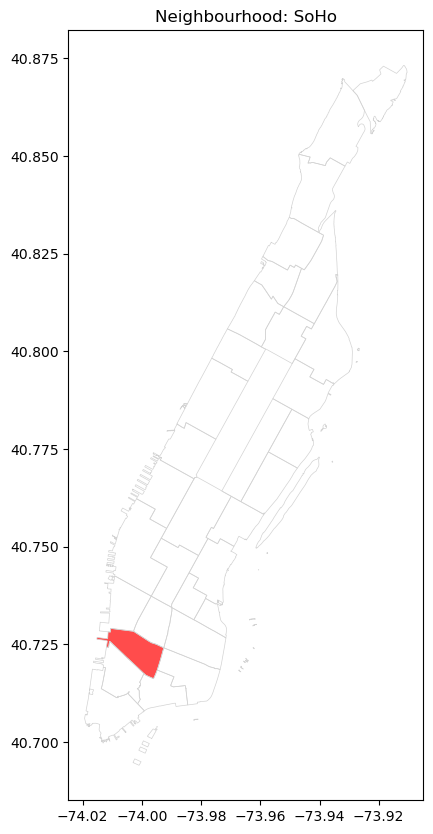

In [57]:
print(f"There are {n} restaurants in {nta_name}.")
show_neighbourhood_map("SoHo")

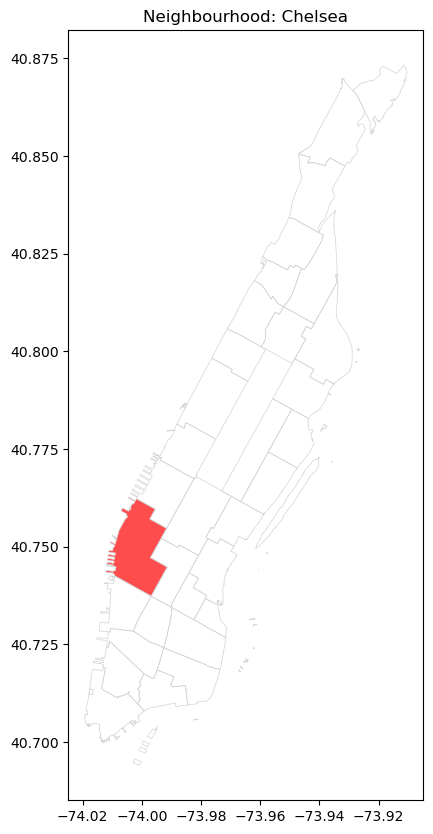

In [58]:
show_neighbourhood_map("Chelsea")

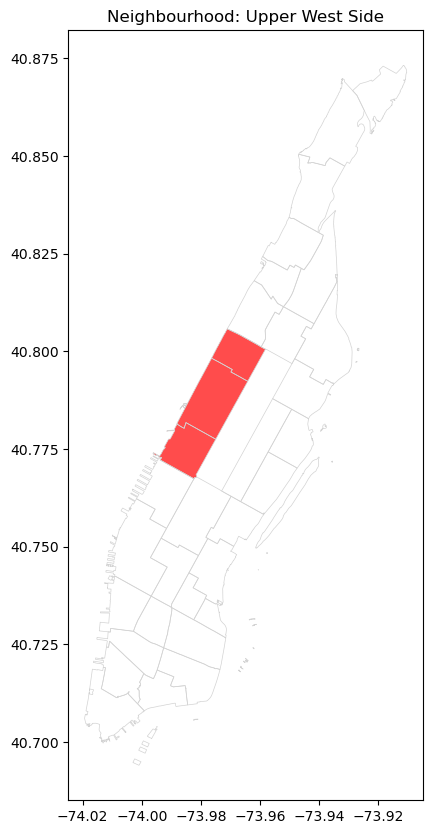

In [59]:
show_neighbourhood_map("Upper West Side")

In [60]:
def run_agent(query):

    print("Received:", query)

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(
                f"Answer: There are {n} restaurants in {nta_name}."
            )

            show_neighbourhood_map(neighbourhood)

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    return "I don't yet know how to answer that question."

Received: How many restaurants are there in SoHo?
Answer: There are 185 restaurants in SoHo-Little Italy-Hudson Square.


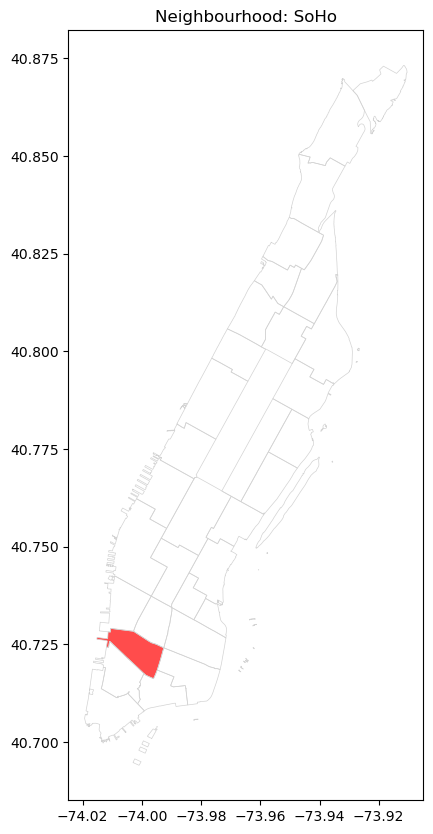

'There are 185 restaurants in SoHo-Little Italy-Hudson Square.'

In [61]:
run_agent("How many restaurants are there in SoHo?")

In [62]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["element"] == "restaurant")
        &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey"
    )

    nta.plot(
        ax=ax,
        color="lightblue",
        alpha=0.5
    )

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=8
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

ValueError: aspect must be finite and positive 

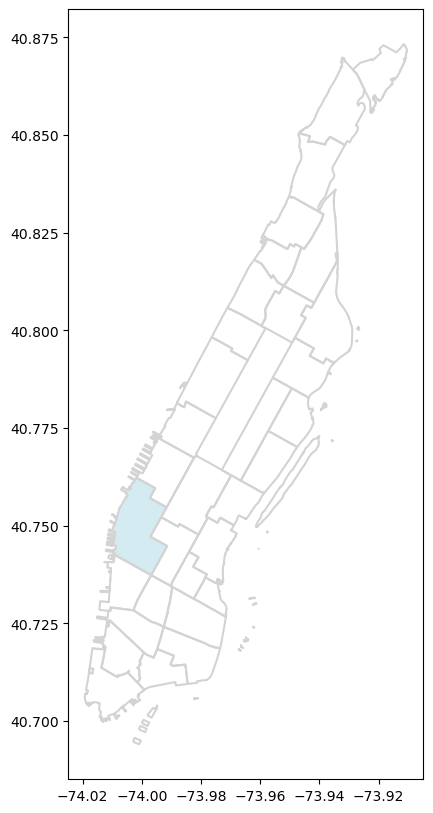

In [63]:
show_restaurants_map("Chelsea")

In [64]:
print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [65]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print("NTA Name:", nta_name)

restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == nta_name)
]

print("Restaurant records found:", len(restaurants))


NTA Name: Chelsea-Hudson Yards
Restaurant records found: 156


In [66]:
print(
    pois_with_nta["ntaname"]
    .dropna()
    .unique()[:20]
)

['Financial District-Battery Park City' 'Midtown-Times Square'
 'Washington Heights (South)' 'Chelsea-Hudson Yards' 'Harlem (North)'
 'East Village' 'Harlem (South)'
 'Upper East Side-Lenox Hill-Roosevelt Island'
 'Upper West Side-Lincoln Square' 'Chinatown-Two Bridges'
 'Murray Hill-Kips Bay' 'East Midtown-Turtle Bay' 'East Harlem (South)'
 'Upper East Side-Carnegie Hill' 'SoHo-Little Italy-Hudson Square'
 'Upper West Side (Central)' 'Tribeca-Civic Center' 'West Village'
 "Hell's Kitchen" 'Hamilton Heights-Sugar Hill']


In [67]:
pois_with_nta[
    pois_with_nta["ntaname"].str.contains(
        "Chelsea",
        case=False,
        na=False
    )
].head()

,element,id,amenity,geometry,ntaname
8,node,357561095,school,POINT (-74.00472 40.74528),Chelsea-Hudson Yards
131,node,357621536,school,POINT (-74.00269 40.74276),Chelsea-Hudson Yards
147,node,357621884,school,POINT (-74.00501 40.74669),Chelsea-Hudson Yards
228,node,368051665,theatre,POINT (-74.00151 40.74395),Chelsea-Hudson Yards
230,node,368051674,theatre,POINT (-74.00111 40.7425),Chelsea-Hudson Yards


In [68]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    print(f"NTA: {nta_name}")
    print(f"Restaurants: {n}")

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    print("Rows returned:", len(restaurants))

    if restaurants.empty:
        print("No restaurant points found.")
        return

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey"
    )

    nta.plot(
        ax=ax,
        color="lightblue",
        alpha=0.5
    )

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=12
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

NTA: Chelsea-Hudson Yards
Restaurants: 156
Rows returned: 156


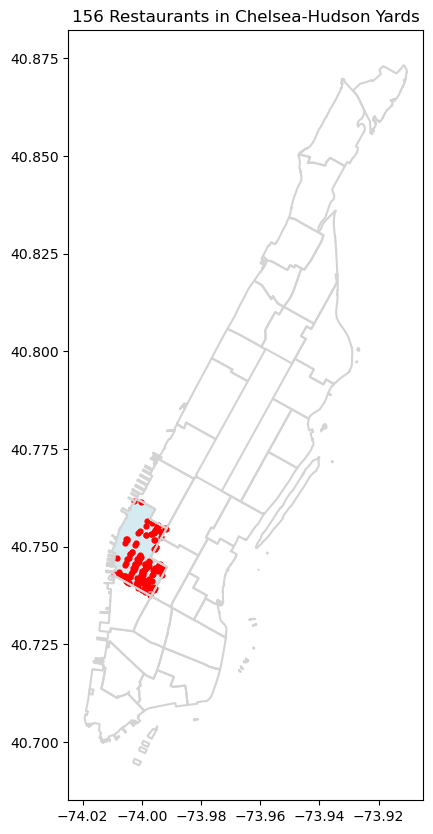

In [69]:
show_restaurants_map("Chelsea")

In [70]:
print("NTA:", nta_name)
print("Rows:", len(restaurants))

NTA: Chelsea-Hudson Yards
Rows: 156


In [71]:
print(restaurants.crs)
print(restaurants.geometry.head())
print(restaurants.geometry.isna().sum())

EPSG:4326
2174    POINT (-73.99355 40.75244)
2463    POINT (-74.00484 40.74216)
2533    POINT (-73.99581 40.75372)
2534    POINT (-73.99543 40.75426)
2535    POINT (-73.99534 40.75438)
Name: geometry, dtype: geometry
0


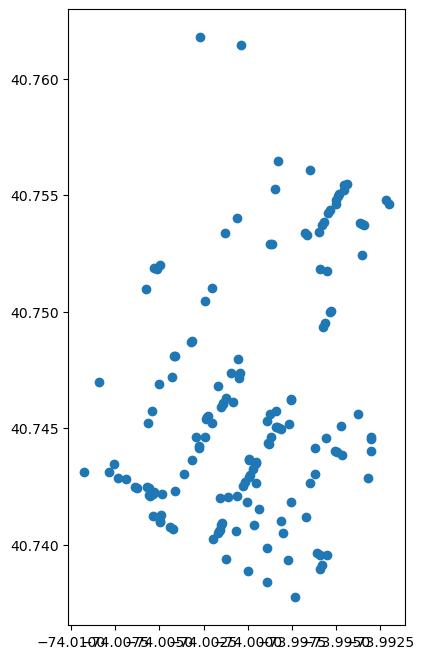

In [72]:
restaurants.plot(figsize=(8,8))
plt.show()

In [73]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    # Remove missing geometries
    restaurants = restaurants[
        restaurants.geometry.notnull()
    ]

    print(f"NTA: {nta_name}")
    print(f"Restaurant points: {len(restaurants)}")

    if len(restaurants) == 0:
        print("No restaurant points found.")
        return

    fig, ax = plt.subplots(figsize=(10,10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    if not nta.empty:
        nta.plot(
            ax=ax,
            color="lightblue",
            alpha=0.5
        )

    # Plot x/y explicitly
    ax.scatter(
        restaurants.geometry.x,
        restaurants.geometry.y,
        c="red",
        s=10,
        label="Restaurants"
    )

    plt.title(f"{n} Restaurants in {nta_name}")
    plt.legend()
    plt.show()

NTA: Chelsea-Hudson Yards
Restaurant points: 156


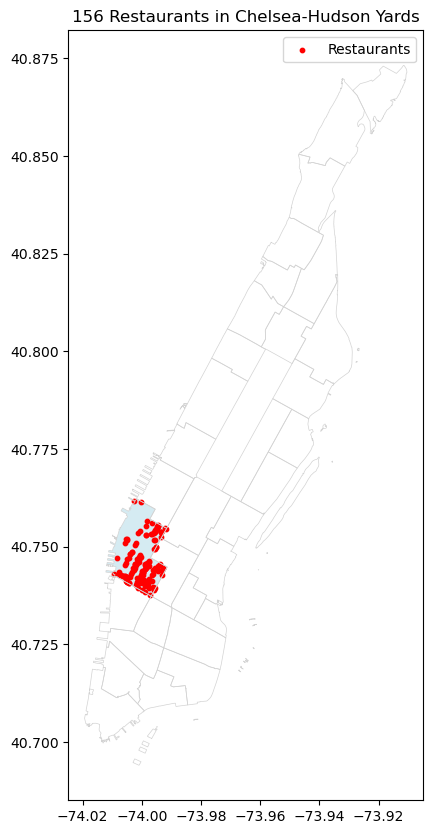

In [74]:
show_restaurants_map("Chelsea")

In [75]:
m = restaurant_map("Chelsea")
m

NameError: name 'restaurant_map' is not defined

<Axes: >

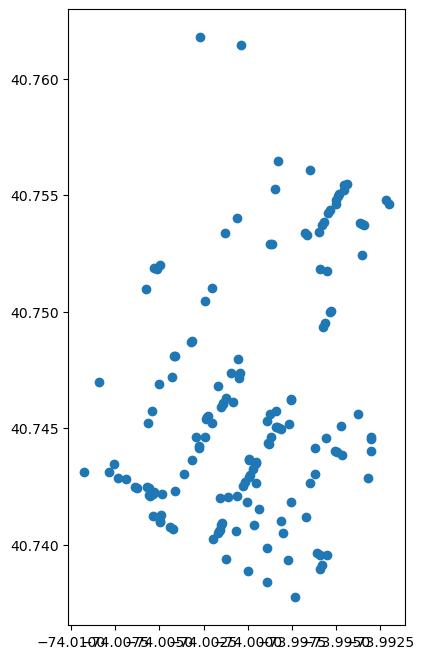

In [76]:
restaurants.plot(figsize=(8,8))

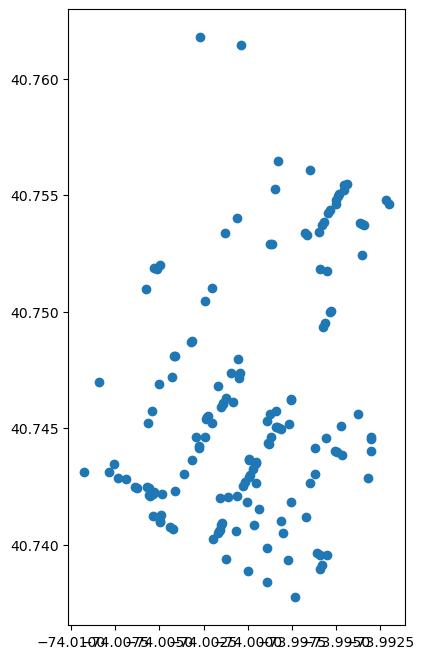

In [77]:
restaurants.plot(figsize=(8,8))
plt.show()

In [78]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10,10))

    # Plot all neighbourhood boundaries
    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    # Highlight selected neighbourhood
    if len(nta) > 0:
        nta.plot(
            ax=ax,
            color="lightblue",
            alpha=0.5
        )

    # Plot restaurant points using scatter
    ax.scatter(
        restaurants.geometry.x,
        restaurants.geometry.y,
        color="red",
        s=10,
        label="Restaurants"
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    ax.legend()

    plt.show()

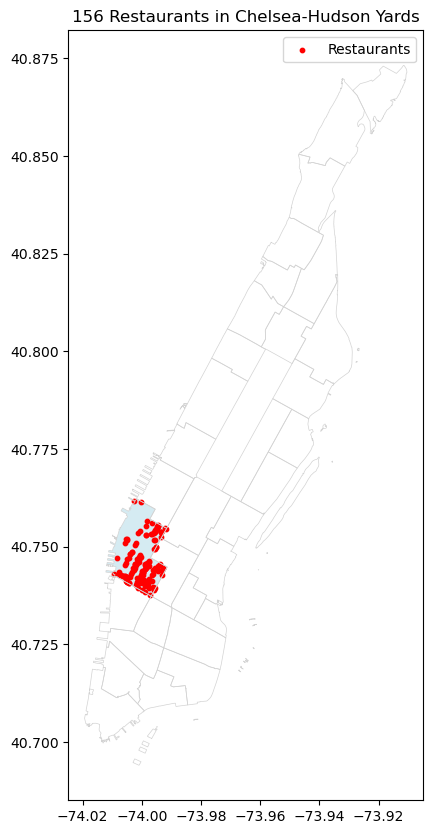

In [79]:
show_restaurants_map("Chelsea")

In [80]:
print(f"There are {n} restaurants in {nta_name}.")
show_restaurants_map(neighbourhood)

There are 156 restaurants in Chelsea-Hudson Yards.


NameError: name 'neighbourhood' is not defined

Received: How many restaurants are there in Chelsea?
Answer: There are 156 restaurants in Chelsea-Hudson Yards.


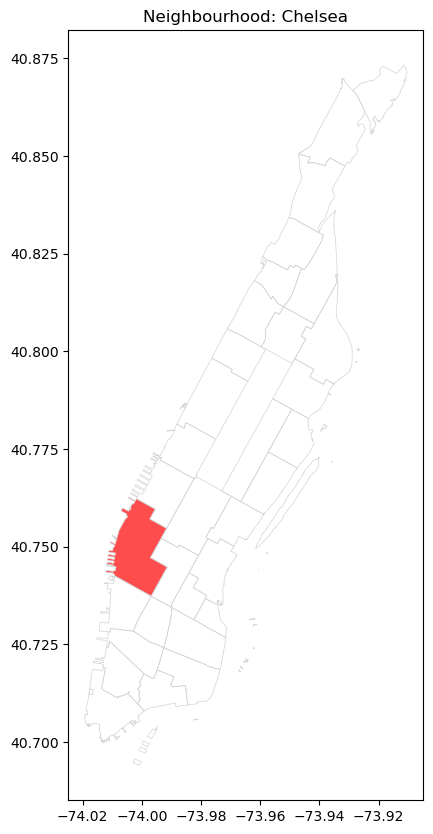

'There are 156 restaurants in Chelsea-Hudson Yards.'

In [81]:
run_agent("How many restaurants are there in Chelsea?")

In [82]:
m = restaurant_map("Chelsea")
m

NameError: name 'restaurant_map' is not defined

In [83]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=row["amenity"]
        ).add_to(m)

    return m

In [84]:
m = restaurant_map("Chelsea")
m

C:\Users\User\AppData\Local\Temp\ipykernel_14008\4168702903.py:20: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


In [85]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == "Chelsea-Hudson Yards")
]

print(len(restaurants))


156


In [86]:
folium.GeoJson(
    nta.__geo_interface__,
    style_function=lambda x: {
        "fillColor": "lightblue",
        "color": "blue",
        "weight": 2,
        "fillOpacity": 0.3
    }
).add_to(m)

NameError: name 'nta' is not defined

In [87]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=row["amenity"]
        ).add_to(m)

    return m

In [88]:
m = restaurant_map("Chelsea")
m

C:\Users\User\AppData\Local\Temp\ipykernel_14008\4168702903.py:20: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


In [89]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == "Chelsea-Hudson Yards")
]

print(len(restaurants))

156


In [90]:
folium.GeoJson(
    nta.__geo_interface__,
    style_function=lambda x: {
        "fillColor": "lightblue",
        "color": "blue",
        "weight": 2,
        "fillOpacity": 0.3
    }
).add_to(m)

NameError: name 'nta' is not defined

In [91]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    # NTA polygon
    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    # Restaurant points
    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if restaurants.empty:
        print("No restaurants found.")
        return None

    # Centre map
    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Add neighbourhood boundary
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Add restaurant points
    for _, row in restaurants.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8
        ).add_to(m)

    return m

In [92]:
m = restaurant_map("Chelsea")
m

C:\Users\User\AppData\Local\Temp\ipykernel_14008\3934940061.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


In [93]:
restaurant_map("SoHo")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\3934940061.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


In [94]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(f"Answer: There are {n} restaurants in {nta_name}.")

            # Display interactive map
            mapp = restaurant_map(neighbourhood)

            if mapp is not None:
                display(mapp)

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."
      

In [95]:
run_agent("How many restaurants are there in Chelsea?")

Answer: There are 156 restaurants in Chelsea-Hudson Yards.


C:\Users\User\AppData\Local\Temp\ipykernel_14008\3934940061.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'There are 156 restaurants in Chelsea-Hudson Yards.'

In [96]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Neighbourhood boundary
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Restaurant points
    for _, row in restaurants.iterrows():

        # Use name column if available
        name = row.get("name", "Restaurant")

        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=name
        ).add_to(m)

    return m

In [97]:
print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [98]:
pois_with_nta.head()

,element,id,amenity,geometry,ntaname
0,node,166878947,ferry_terminal,POINT (-74.0055 40.70245),Financial District-Battery Park City
1,node,291921307,drinking_water,POINT (-73.95821 40.79943),NaN
2,node,291921309,drinking_water,POINT (-73.95537 40.79287),NaN
3,node,291921311,drinking_water,POINT (-73.95563 40.7922),NaN
4,node,322546340,toilets,POINT (-73.97123 40.77352),NaN


In [99]:
popup=f"Restaurant ID: {row['id']}"

NameError: name 'row' is not defined

In [100]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    # COUNT RESTAURANTS
    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(f"There are {n} restaurants in {nta_name}.")

            display(restaurant_map(neighbourhood))

            return f"There are {n} restaurants in {nta_name}."

    # SHOW RESTAURANTS
    if "show restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(restaurant_map(neighbourhood))

            return f"Showing restaurants in {neighbourhood}."

    return "I don't yet know how to answer that question."

In [101]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if restaurants.empty:
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Neighborhood polygon
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Restaurant locations
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    return m

In [103]:
run_agent("Show restaurants in Chelsea")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\1504028089.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'Showing restaurants in Chelsea.'

In [104]:
run_agent("Show restaurants in SoHo")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\1504028089.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'Showing restaurants in SoHo.'

In [105]:
print(pois.head())

NameError: name 'pois' is not defined

In [106]:
print(pois.columns)

NameError: name 'pois' is not defined

In [107]:
for _, row in restaurants.iterrows():

    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.8,
        popup=f"OSM ID: {row['id']}"
    ).add_to(m)

In [108]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    # Count restaurants
    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(restaurant_map(neighbourhood))

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    # Show restaurants
    elif "show restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                restaurant_map(neighbourhood)
            )

            return (
                f"Showing restaurants in "
                f"{neighbourhood}."
            )

    return "I don't yet know how to answer that question."

In [109]:
run_agent("Show restaurants in Chelsea")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\1504028089.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'Showing restaurants in Chelsea.'

In [110]:
run_agent("Show restaurants in SoHo")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\1504028089.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'Showing restaurants in SoHo.'

In [112]:
run_agent("How many restaurants are there in Harlem?")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\1504028089.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = restaurants.geometry.unary_union.centroid


'There are 176 restaurants in Harlem (South).'

In [113]:
VALID_CATEGORIES = set(
    pois_with_nta["amenity"]
    .dropna()
    .unique()
)

In [114]:
sorted(list(VALID_CATEGORIES))[:50]

['School Supply Store',
 'animal_boarding',
 'animal_shelter',
 'arts_centre',
 'atm',
 'bank',
 'bar',
 'bbq',
 'bench',
 'bicycle_parking',
 'bicycle_rental',
 'bicycle_repair_station',
 'biergarten',
 'binoculars',
 'boat_rental',
 'brewery',
 'bureau_de_change',
 'bus_station',
 'cafe',
 'cafe;bar',
 'car_rental',
 'car_sharing',
 'car_wash',
 'charging_station',
 'childcare',
 'cinema',
 'clear',
 'clinic',
 'clock',
 'college',
 'community_centre',
 'compressed_air',
 'conference_centre',
 'convenience',
 'courthouse',
 'coworking_space',
 'dance_school',
 'dancing_school',
 'dentist',
 'device_charging_station',
 'disused',
 'doctors',
 'dojo',
 'dormitory',
 'drinking_water',
 'driving_school',
 'events_venue',
 'fast_food',
 'ferry_terminal',
 'fire_station']

In [115]:
import folium

def amenity_map(category, neighbourhood):

    nta_name, n = count_pois(
        category=category,
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    places = pois_with_nta[
        (pois_with_nta["amenity"] == category) &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if places.empty:
        print("No locations found.")
        return None

    centre = places.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    if not nta.empty:

        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    for _, row in places.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"{category} (ID {row['id']})"
        ).add_to(m)

    return m

In [116]:
def find_category(query):

    q = query.lower()

    for cat in VALID_CATEGORIES:

        if str(cat).lower() in q:
            return cat

    return None

In [117]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    category = find_category(query)

    #
    # COUNT QUERY
    #
    if "how many" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category=category,
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"There are {n} "
                f"{category}s in "
                f"{nta_name}."
            )

    #
    # SHOW QUERY
    #
    if "show" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"Showing {category}s "
                f"in {neighbourhood}."
            )

    #
    # RANKING QUERY
    #
    if "most" in q and category:

        return rank_neighbourhoods(category)

    #
    # SOHO DESCRIPTION
    #
    if "what kind of neighbourhood" in q:

        m = re.search(r"is (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            return summarise_neighbourhood_simple(
                neighbourhood
            )

    #
    # FINANCIAL DISTRICT NEARBY
    #
    if "nearby" in q or "within 1 km" in q:

        return nearby_food(
            40.706,
            -74.011,
            1000
        )

    return (
        "I don't yet know how to "
        "answer that question."
    )

In [118]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 156 restaurants in Chelsea-Hudson Yards.'

In [119]:
run_agent(
    "How many cafes are there in Harlem?"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 38 cafes in Harlem (North).'

In [120]:
run_agent(
    "How many bars are there in SoHo?"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 26 bars in SoHo-Little Italy-Hudson Square.'

In [121]:
run_agent(
    "Show restaurants in Chelsea"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'Showing restaurants in Chelsea.'

In [122]:
run_agent(
    "Which neighbourhood has the most restaurants?"
)

NameError: name 'rank_neighbourhoods' is not defined

In [123]:
run_agent(
    "Which neighbourhood has the most cafes?"
)

NameError: name 'rank_neighbourhoods' is not defined

In [124]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)

NameError: name 'summarise_neighbourhood_simple' is not defined

In [125]:
summarise_neighbourhood_simple("SoHo")

NameError: name 'summarise_neighbourhood_simple' is not defined

In [126]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    category = find_category(query)

    # COUNT QUERY
    if "how many" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category=category,
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"There are {n} {category}s in "
                f"{nta_name}."
            )

    # SHOW QUERY
    elif "show" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"Showing {category}s in "
                f"{neighbourhood}."
            )

    # RANK QUERY
    elif "most" in q and category:

        return rank_neighbourhoods(category)

    # DESCRIBE NEIGHBOURHOOD
    elif (
        "what kind of neighbourhood" in q
        or "describe" in q
        or "tell me about" in q
    ):

        m = re.search(
            r"(?:is|about)\s+(.+?)\??$",
            query,
            re.IGNORECASE
        )

        if m:

            neighbourhood = m.group(1).strip()

            return summarise_neighbourhood_simple(
                neighbourhood
            )

    # NEARBY FOOD
    elif (
        "nearby" in q
        or "within 1 km" in q
        or "food options" in q
    ):

        return nearby_food(
            40.706,
            -74.011,
            1000
        )

    return "I don't yet know how to answer that question."

In [127]:
run_agent("What kind of neighbourhood is SoHo?")

NameError: name 'summarise_neighbourhood_simple' is not defined

In [128]:
run_agent("Describe Chelsea")

"I don't yet know how to answer that question."

In [129]:
run_agent("How many cafes are there in Chelsea?")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 68 cafes in Chelsea-Hudson Yards.'

In [130]:
summarise_neighbourhood_simple("SoHo")

NameError: name 'summarise_neighbourhood_simple' is not defined

In [131]:
import inspect
print(inspect.getsource(summarise_neighbourhood_simple))

NameError: name 'summarise_neighbourhood_simple' is not defined

In [132]:
summarise_neighbourhood_simple("SoHo")

NameError: name 'summarise_neighbourhood_simple' is not defined

In [133]:
import inspect
print(inspect.getsource(summarise_neighbourhood_simple))

NameError: name 'summarise_neighbourhood_simple' is not defined

In [134]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

    summary = (
        f"{neighbourhood} contains "
        f"{len(subset)} mapped amenities. "
        f"The most common amenities are:\n\n"
    )

    for amenity, count in top.items():
        summary += f"• {amenity}: {count}\n"

    return summary

In [135]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities. The most common amenities are:

• bicycle_parking: 218
• restaurant: 185
• bench: 121
• waste_basket: 95
• cafe: 73
• fast_food: 37
• bar: 26
• post_box: 22
• bank: 22
• bicycle_rental: 19



In [136]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if subset.empty:
        return "Neighbourhood not found."

    total = len(subset)

    restaurants = (
        subset["amenity"] == "restaurant"
    ).sum()

    cafes = (
        subset["amenity"] == "cafe"
    ).sum()

    bars = (
        subset["amenity"] == "bar"
    ).sum()

    top = subset["amenity"].value_counts().head(5)

    text = (
        f"{neighbourhood} contains "
        f"{total} mapped amenities.\n\n"
        f"Restaurants: {restaurants}\n"
        f"Cafes: {cafes}\n"
        f"Bars: {bars}\n\n"
        f"Top amenity categories:\n"
    )

    for amenity, count in top.items():
        text += f"- {amenity}: {count}\n"

    return text

In [137]:
count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

('Chelsea-Hudson Yards', 156)

In [138]:
amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


In [139]:
amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


In [140]:
rank_neighbourhoods("restaurant")

NameError: name 'rank_neighbourhoods' is not defined

In [141]:
summarise_neighbourhood_simple("SoHo")

'SoHo contains 937 mapped amenities.\n\nRestaurants: 185\nCafes: 73\nBars: 26\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n'

In [142]:
nearby_food(
    40.706,
    -74.011,
    1000
)

NameError: name 'nearby_food' is not defined

In [143]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 156 restaurants in Chelsea-Hudson Yards.'

In [144]:
run_agent(
    "Show restaurants in SoHo"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'Showing restaurants in SoHo.'

In [145]:
run_agent(
    "Which neighbourhood has the most cafes?"
)

NameError: name 'rank_neighbourhoods' is not defined

In [146]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)


'SoHo contains 937 mapped amenities.\n\nRestaurants: 185\nCafes: 73\nBars: 26\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n'

In [147]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = ...

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

In [148]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

    text = (
        f"{neighbourhood} contains "
        f"{len(subset)} mapped amenities.\n\n"
        f"Top amenity categories:\n"
    )

    for amenity, count in top.items():
        text += f"- {amenity}: {count}\n"

    return text

In [149]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [150]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

Chelsea-Hudson Yards
156


In [151]:
m = amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

m

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


In [152]:
m = amenity_map(
    category="cafe",
    neighbourhood="SoHo"
)

m

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


In [153]:
rank_neighbourhoods("restaurant")

NameError: name 'rank_neighbourhoods' is not defined

In [154]:
rank_neighbourhoods("cafe")

NameError: name 'rank_neighbourhoods' is not defined

In [155]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [156]:
print(
    summarise_neighbourhood_simple("Chelsea")
)

Chelsea contains 1192 mapped amenities.

Top amenity categories:
- bicycle_parking: 259
- bench: 255
- restaurant: 156
- fast_food: 70
- cafe: 68
- waste_basket: 54
- bicycle_rental: 41
- bar: 40
- drinking_water: 28
- parking_entrance: 18



In [157]:
nearby_food(
    40.706,
    -74.011,
    1000
)

NameError: name 'nearby_food' is not defined

In [158]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 156 restaurants in Chelsea-Hudson Yards.'

In [159]:
run_agent(
    "Which neighbourhood has the most restaurants?"
)

NameError: name 'rank_neighbourhoods' is not defined

In [160]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)

'SoHo contains 937 mapped amenities.\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n- fast_food: 37\n- bar: 26\n- post_box: 22\n- bank: 22\n- bicycle_rental: 19\n'

In [161]:
run_agent(
    "What food options are near the Financial District?"
)

NameError: name 'nearby_food' is not defined

In [162]:
print("="*60)
print("TEST 1: count_pois")
print(count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
))

print("="*60)
print("TEST 2: rank_neighbourhoods")
print(rank_neighbourhoods("restaurant"))

print("="*60)
print("TEST 3: summarise_neighbourhood_simple")
print(summarise_neighbourhood_simple("SoHo"))

print("="*60)
print("TEST 4: nearby_food")
print(nearby_food(
    40.706,
    -74.011,
    1000
))

TEST 1: count_pois
('Chelsea-Hudson Yards', 156)
TEST 2: rank_neighbourhoods


NameError: name 'rank_neighbourhoods' is not defined

In [163]:
print("="*60)
print("TEST 1: count_pois")
print(
    count_pois(
        category="restaurant",
        neighbourhood="Chelsea",
        pois_gdf=pois_with_nta
    )
)

print("\n" + "="*60)
print("TEST 2: rank_neighbourhoods")
print(
    rank_neighbourhoods("restaurant")
)

print("\n" + "="*60)
print("TEST 3: summarise_neighbourhood_simple")
print(
    summarise_neighbourhood_simple("SoHo")
)

print("\n" + "="*60)
print("TEST 4: nearby_food")
print(
    nearby_food(
        40.706,
        -74.011,
        1000
    )
)

print("\n" + "="*60)
print("TEST 5: restaurant map")

m = restaurant_map("Chelsea")

if m is not None:
    print("✓ Map created successfully")
else:
    print("✗ Map creation failed")

TEST 1: count_pois
('Chelsea-Hudson Yards', 156)

TEST 2: rank_neighbourhoods


NameError: name 'rank_neighbourhoods' is not defined

In [164]:
test_queries = [
    "How many restaurants are there in Chelsea?",
    "Show restaurants in SoHo",
    "Which neighbourhood has the most restaurants?",
    "What kind of neighbourhood is SoHo?",
    "What food options are near the Financial District?"
]

for q in test_queries:

    print("\n" + "=" * 80)
    print("QUERY:", q)

    try:
        result = run_agent(q)

        print("RESULT:")
        print(result)

    except Exception as e:
        print("ERROR:")
        print(e)


QUERY: How many restaurants are there in Chelsea?


C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


RESULT:
There are 156 restaurants in Chelsea-Hudson Yards.

QUERY: Show restaurants in SoHo


C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


RESULT:
Showing restaurants in SoHo.

QUERY: Which neighbourhood has the most restaurants?
ERROR:
name 'rank_neighbourhoods' is not defined

QUERY: What kind of neighbourhood is SoHo?
RESULT:
SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19


QUERY: What food options are near the Financial District?
ERROR:
name 'nearby_food' is not defined


In [165]:
#Create an interactive nearby-food map
import folium

def nearby_food_map(lat, lon, radius_m):

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius_m
    )

    m = folium.Map(
        location=[lat, lon],
        zoom_start=15
    )

    # Query location
    folium.Marker(
        [lat, lon],
        popup="Search Location",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Restaurants
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    # Cafes
    for _, row in cafes.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="blue",
            fill=True,
            popup=f"Cafe ID: {row['id']}"
        ).add_to(m)

    return m



In [166]:
import inspect

print(inspect.getsource(count_pois))

def count_pois(category, neighbourhood, pois_gdf):

    result = pois_gdf[
        (pois_gdf["amenity"].str.lower() == category.lower())
        &
        (
            pois_gdf["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    count = len(result)

    if count > 0:
        nta_name = result["ntaname"].iloc[0]
    else:
        nta_name = neighbourhood

    return nta_name, count



In [167]:
elif (
    "near" in q
    or "nearby" in q
    or "food options" in q
):
    
    lat = 40.706
    lon = -74.011
    radius = 1000

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius
    )

    display(
        nearby_food_map(
            lat,
            lon,
            radius
        )
    )

    return (
        f"There are {len(restaurants)} restaurants "
        f"and {len(cafes)} cafes within "
        f"{radius} metres."
    )

SyntaxError: invalid syntax (1349702673.py, line 1)

In [168]:
with open("src/analytics.py", "r", encoding="utf-8") as f:
    print(f.read())

# src/analytics.py

import geopandas as gpd
from shapely.geometry import Point


def count_pois(
    category,
    neighbourhood,
    pois_gdf
):
    """
    Count amenities within a neighbourhood.
    """

    subset = pois_gdf[
        (
            pois_gdf["amenity"]
            .str.lower()
            == category.lower()
        )
        &
        (
            pois_gdf["ntaname"]
            .str.contains(
                neighbourhood,
                case=False,
                na=False
            )
        )
    ]

    n = len(subset)

    if n == 0:
        return None, 0

    nta_name = subset.iloc[0]["ntaname"]

    return nta_name, n


def summarise_neighbourhood_simple(
    neighbourhood,
    pois_gdf
):
    """
    Create a simple neighbourhood profile.
    """

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if subset.empty:
        return "Neighbour

In [169]:
from src.analytics import (
    count_pois,
    rank_neighbourhoods,
    summarise_neighbourhood_simple,
    nearby_food
)

print("Analytics module imported successfully!")

ImportError: cannot import name 'rank_neighbourhoods' from 'src.analytics' (C:\Users\User\Desktop\GEOAI\src\analytics.py)

In [170]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

Chelsea-Hudson Yards
156


In [171]:
%whos


Variable                         Type             Data/Info
-----------------------------------------------------------
VALID_CATEGORIES                 set              {'bbq', 'monastery', 'spa<...>ue', 'conference_centre'}
amenity_map                      function         <function amenity_map at 0x0000029150F754E0>
cell                             dict             n=6
count_pois                       function         <function count_pois at 0x000002914864DD00>
dirs                             list             n=0
display                          function         <function display at 0x0000029145F47880>
f                                TextIOWrapper    <_io.TextIOWrapper name='<...>ode='r' encoding='utf-8'>
file                             str              __init__.cpython-313.pyc
files                            list             n=5
find_category                    function         <function find_category at 0x00000291506BED40>
folium                           module           <mod

In [172]:
from src.analytics import (
    count_pois,
    rank_neighbourhoods,
    summarise_neighbourhood_simple,
    nearby_food
)

print("✅ analytics.py imported successfully")

ImportError: cannot import name 'rank_neighbourhoods' from 'src.analytics' (C:\Users\User\Desktop\GEOAI\src\analytics.py)

In [173]:
help(count_pois)

Help on function count_pois in module src.analytics:

count_pois(category, neighbourhood, pois_gdf)
    Count amenities within a neighbourhood.



In [174]:
from src.analytics import (
    count_pois,
    rank_neighbourhoods,
    summarise_neighbourhood_simple,
    nearby_food
)

print("✅ Analytics module loaded successfully")

ImportError: cannot import name 'rank_neighbourhoods' from 'src.analytics' (C:\Users\User\Desktop\GEOAI\src\analytics.py)

In [175]:
from src.mapping import hello_map

m = hello_map()

m

ImportError: cannot import name 'hello_map' from 'src.mapping' (C:\Users\User\Desktop\GEOAI\src\mapping.py)

In [176]:
amenity_map

<function __main__.amenity_map(category, neighbourhood)>

In [177]:
import folium

def nearby_food_map(lat, lon, radius_m):

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius_m
    )

    m = folium.Map(
        location=[lat, lon],
        zoom_start=15
    )

    # Search location
    folium.Marker(
        [lat, lon],
        popup="Financial District",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Search radius
    folium.Circle(
        location=[lat, lon],
        radius=radius_m,
        color="green",
        fill=False
    ).add_to(m)

    # Restaurants
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    # Cafes
    for _, row in cafes.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="blue",
            fill=True,
            fill_opacity=0.8,
            popup=f"Cafe ID: {row['id']}"
        ).add_to(m)

    return m

In [178]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

NameError: name 'nearby_food' is not defined

In [179]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000
)


NameError: name 'nearby_food' is not defined

In [180]:
print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 156


NameError: name 'cafes' is not defined

In [181]:
for _, row in restaurants.iterrows():
    print(row.geometry.y, row.geometry.x)

40.7524435 -73.9935503
40.7421638 -74.0048429
40.7537214 -73.995808
40.7542567 -73.9954338
40.7543769 -73.9953394
40.7533878 -73.9967808
40.753864 -73.9956804
40.7532964 -73.9966423
40.7424674 -74.005715
40.7396323 -73.996068
40.7395688 -73.9959132
40.7391381 -73.9957765
40.7398784 -73.9989355
40.744378 -73.9988791
40.7549873 -73.9948837
40.7546155 -73.9949991
40.7462866 -74.0012226
40.7452438 -74.0056781
40.742976 -73.9998997
40.7420517 -74.001097
40.7425418 -74.0002463
40.7426738 -74.0001725
40.7432349 -73.9997149
40.7420719 -74.0006086
40.7429148 -73.9999442
40.7446356 -73.9986916
40.7462136 -73.9975429
40.7434448 -73.9995835
40.749979 -73.9953383
40.750033 -73.995284
40.7457288 -73.998418
40.7456072 -73.9987643
40.7460875 -74.0013739
40.7460286 -74.0014102
40.7458946 -74.0014911
40.7452195 -74.0020025
40.7446425 -74.0024036
40.7442217 -74.0027401
40.7441697 -74.0027774
40.7436469 -74.0031642
40.7395596 -73.9954916
40.7473898 -74.0004115
40.7405843 -74.0016421
40.7406485 -74.0015951

In [182]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000
)

NameError: name 'nearby_food' is not defined

In [183]:
print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 156


NameError: name 'cafes' is not defined

In [184]:
for _, row in restaurants.iterrows():
    print(row.geometry.y, row.geometry.x)

40.7524435 -73.9935503
40.7421638 -74.0048429
40.7537214 -73.995808
40.7542567 -73.9954338
40.7543769 -73.9953394
40.7533878 -73.9967808
40.753864 -73.9956804
40.7532964 -73.9966423
40.7424674 -74.005715
40.7396323 -73.996068
40.7395688 -73.9959132
40.7391381 -73.9957765
40.7398784 -73.9989355
40.744378 -73.9988791
40.7549873 -73.9948837
40.7546155 -73.9949991
40.7462866 -74.0012226
40.7452438 -74.0056781
40.742976 -73.9998997
40.7420517 -74.001097
40.7425418 -74.0002463
40.7426738 -74.0001725
40.7432349 -73.9997149
40.7420719 -74.0006086
40.7429148 -73.9999442
40.7446356 -73.9986916
40.7462136 -73.9975429
40.7434448 -73.9995835
40.749979 -73.9953383
40.750033 -73.995284
40.7457288 -73.998418
40.7456072 -73.9987643
40.7460875 -74.0013739
40.7460286 -74.0014102
40.7458946 -74.0014911
40.7452195 -74.0020025
40.7446425 -74.0024036
40.7442217 -74.0027401
40.7441697 -74.0027774
40.7436469 -74.0031642
40.7395596 -73.9954916
40.7473898 -74.0004115
40.7405843 -74.0016421
40.7406485 -74.0015951

In [185]:
print(restaurants.crs)

EPSG:4326


In [186]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

NameError: name 'cafes' is not defined

In [187]:
for _, row in restaurants_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="red",
        fill=True
    ).add_to(m)

In [188]:
for _, row in cafes_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="blue",
        fill=True
    ).add_to(m)

NameError: name 'cafes_ll' is not defined

In [189]:
count = 0

for _, row in restaurants.iterrows():
    count += 1

print(count)

156


In [190]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup="Restaurant",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup="Cafe",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

NameError: name 'cafes_ll' is not defined

In [191]:
print(restaurants.crs)
print(cafes.crs)

EPSG:4326


NameError: name 'cafes' is not defined

In [192]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

NameError: name 'cafes' is not defined

In [193]:
for _, row in restaurants_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="red",
        fill=True,
        popup=f"Restaurant ID: {row['id']}"
    ).add_to(m)

In [194]:
for _, row in cafes_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="blue",
        fill=True,
        popup=f"Cafe ID: {row['id']}"
    ).add_to(m)

NameError: name 'cafes_ll' is not defined

In [195]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

In [196]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

In [197]:
for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

NameError: name 'cafes_ll' is not defined

In [198]:
print(
    restaurants_ll.geometry.iloc[0]
)

POINT (-73.9935503 40.7524435)


In [199]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

NameError: name 'nearby_food' is not defined

In [200]:
print(restaurants.crs)
print(cafes.crs)

EPSG:4326


NameError: name 'cafes' is not defined

In [201]:
restaurants_ll = restaurants.to_crs(4326)
print(restaurants_ll.geometry.iloc[0])

POINT (-73.9935503 40.7524435)


In [202]:
print("Restaurant markers:", len(restaurants))
print("Cafe markers:", len(cafes))

Restaurant markers: 156


NameError: name 'cafes' is not defined

In [203]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

NameError: name 'cafes_ll' is not defined

In [204]:
restaurants_fg = folium.FeatureGroup(name="Restaurants")
cafes_fg = folium.FeatureGroup(name="Cafes")

# add markers to each group

restaurants_fg.add_to(m)
cafes_fg.add_to(m)

folium.LayerControl().add_to(m)

In [205]:
print(restaurants.crs)

restaurants_ll = restaurants.to_crs(4326)

print(restaurants_ll.geometry.iloc[0])
print(len(restaurants_ll))

EPSG:4326
POINT (-73.9935503 40.7524435)
156


In [206]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}"
    ).add_to(m)

In [207]:
from folium.plugins import MarkerCluster

In [208]:
cluster = MarkerCluster().add_to(m)

In [209]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red", icon="cutlery", prefix="fa")
    ).add_to(cluster)

In [210]:
for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue", icon="coffee", prefix="fa")
    ).add_to(cluster)

NameError: name 'cafes_ll' is not defined

In [211]:
folium.Circle(
    location=[lat, lon],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

NameError: name 'lat' is not defined

In [212]:
print("Restaurants:", len(restaurants_ll))
print("Cafes:", len(cafes_ll))

Restaurants: 156


NameError: name 'cafes_ll' is not defined

In [213]:
print(f"Restaurant markers added: {len(restaurants_ll)}")
print(f"Cafe markers added: {len(cafes_ll)}")

Restaurant markers added: 156


NameError: name 'cafes_ll' is not defined

In [214]:
folium.Circle(
    location=[40.706, -74.011],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

In [215]:
from folium.plugins import MarkerCluster

m = folium.Map(
    location=[40.706, -74.011],
    zoom_start=15
)

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

folium.Circle(
    location=[40.706, -74.011],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

NameError: name 'cafes_ll' is not defined

In [ ]:
from src.analytics import count_pois

In [216]:
import os

print(os.getcwd())

C:\Users\User\Desktop\GEOAI


In [217]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'cache', 'Code', 'config.txt', 'data', 'GEOAI project.ipynb', 'geoai-manhattan-explorer', 'geoai_functions.txt', 'GitHub README.txt', 'notebooks', 'notebook_history.py', 'requirements.txt', 'screenshots', 'src']


In [218]:
print(os.listdir("src"))

['agent.py', 'analytics.py', 'data_loader.py', 'mapping.py', '__init__.py', '__pycache__']


In [219]:
import os

os.rename(
    "src/analytics.py.txt",
    "src/analytics.py"
)

print(os.listdir("src"))

FileNotFoundError: [WinError 2] The system cannot find the file specified: 'src/analytics.py.txt' -> 'src/analytics.py'

In [220]:
print(os.listdir("src"))

['agent.py', 'analytics.py', 'data_loader.py', 'mapping.py', '__init__.py', '__pycache__']


In [221]:
from src.analytics import count_pois

print("Import successful")

Import successful


In [222]:
with open("src/analytics.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines, start=1):
    print(f"{i}: {line.rstrip()}")

1: # src/analytics.py
2: 
3: import geopandas as gpd
4: from shapely.geometry import Point
5: 
6: 
7: def count_pois(
8:     category,
9:     neighbourhood,
10:     pois_gdf
11: ):
12:     """
13:     Count amenities within a neighbourhood.
14:     """
15: 
16:     subset = pois_gdf[
17:         (
18:             pois_gdf["amenity"]
19:             .str.lower()
20:             == category.lower()
21:         )
22:         &
23:         (
24:             pois_gdf["ntaname"]
25:             .str.contains(
26:                 neighbourhood,
27:                 case=False,
28:                 na=False
29:             )
30:         )
31:     ]
32: 
33:     n = len(subset)
34: 
35:     if n == 0:
36:         return None, 0
37: 
38:     nta_name = subset.iloc[0]["ntaname"]
39: 
40:     return nta_name, n
41: 
42: 
43: def summarise_neighbourhood_simple(
44:     neighbourhood,
45:     pois_gdf
46: ):
47:     """
48:     Create a simple neighbourhood profile.
49:     """
50: 
51:     subset = p

In [223]:
lat = 40.706
lon = -74.011

folium.Circle(
    location=[lat, lon],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

In [224]:
from folium.plugins import MarkerCluster

m = folium.Map(
    location=[40.706, -74.011],
    zoom_start=15
)

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}"
    ).add_to(cluster)

m

In [225]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

NameError: name 'cafes' is not defined

In [226]:
    elif (
        "near" in q
        or "nearby" in q
        or "food options" in q
    ):

        display(
            nearby_food_map(
                40.706,
                -74.011,
                1000
            )
        )

        return (
            "Showing restaurants and cafes "
            "within 1 km of the Financial District."
        )

SyntaxError: invalid syntax (916664674.py, line 1)

In [227]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

NameError: name 'nearby_food' is not defined

In [228]:
folium.Circle(
    location=[lat, lon],
    radius=radius_m,
    color="green",
    fill=False
).add_to(m)

NameError: name 'radius_m' is not defined

In [229]:
run_agent(
    "What food options are near the Financial District?"
)

NameError: name 'nearby_food' is not defined

In [230]:
print(
    count_pois(
        category="restaurant",
        neighbourhood="Chelsea",
        pois_gdf=pois_with_nta
    )
)

('Chelsea-Hudson Yards', 156)


In [231]:
print(
    rank_neighbourhoods("restaurant")
)

NameError: name 'rank_neighbourhoods' is not defined

In [232]:
result = summarise_neighbourhood_simple("SoHo")

print(type(result))
print(result)

<class 'str'>
SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [233]:
from src.analytics import count_pois

print("Import successful")

Import successful


In [234]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

Chelsea-Hudson Yards
156


In [235]:
from src.analytics import count_pois

In [236]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

Chelsea-Hudson Yards
156


In [237]:
Edit → Find and Replace

SyntaxError: invalid character '→' (U+2192) (1491652294.py, line 1)

In [238]:
Ctrl + F

NameError: name 'Ctrl' is not defined

In [239]:
from src.analytics import rank_neighbourhoods

rank_neighbourhoods("restaurant")

ImportError: cannot import name 'rank_neighbourhoods' from 'src.analytics' (C:\Users\User\Desktop\GEOAI\src\analytics.py)

In [240]:
test_queries * [
    "How many restaurants are t*ere in Chelsea?",
    "Show restau*ants in SoHo",
    "Which neighbou*hood has the most restaurants?",
 *  "What kind of neighbourhood is S*Ho?",
    "What food options are near the Financial District?"
]

for q in test_queries:
    print("\n" + "="*80)
    print("QUERY:", q)

    try:
        result = run_agent(q)
        print("RESULT:")
        print(result)

    except Exception as e:
        print("ERROR:")
        print(e)

TypeError: can't multiply sequence by non-int of type 'list'

In [241]:
from IPython.display import display

for q in test_queries:

    print("\n" + "="*80)
    print("QUERY:", q)

    try:

        result = run_agent(q)

        if result is not None:
            print(result)

    except Exception as e:

        print("ERROR:", e)


QUERY: How many restaurants are there in Chelsea?


C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


There are 156 restaurants in Chelsea-Hudson Yards.

QUERY: Show restaurants in SoHo


C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


Showing restaurants in SoHo.

QUERY: Which neighbourhood has the most restaurants?
ERROR: name 'rank_neighbourhoods' is not defined

QUERY: What kind of neighbourhood is SoHo?
SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19


QUERY: What food options are near the Financial District?
ERROR: name 'nearby_food' is not defined


In [242]:
summarise_neighbourhood_simple("SoHo")

'SoHo contains 937 mapped amenities.\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n- fast_food: 37\n- bar: 26\n- post_box: 22\n- bank: 22\n- bicycle_rental: 19\n'

In [243]:
run_agent(
    "I'm staying in the Financial District. What restaurants and cafes are nearby?"
)

NameError: name 'nearby_food' is not defined

In [244]:
print(manhattan.columns)

Index(['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname',
       'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020',
       'geometry'],
      dtype='object')


In [245]:
import matplotlib.pyplot as plt

def show_neighbourhood_map(neighbourhood):

    nta = nta_gdf[
        nta_gdf["NTAName"].str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if nta.empty:
        print("Neighbourhood not found.")
        return

    fig, ax = plt.subplots(figsize=(8, 8))

    nta_gdf.boundary.plot(ax=ax, color="lightgrey")
    nta.plot(ax=ax, color="red", alpha=0.6)

    ax.set_title(f"Neighbourhood: {neighbourhood}")
    plt.show()

In [246]:
print(f"There are {n} restaurants in {nta_name}.")
show_neighbourhood_map(neighbourhood)

There are 156 restaurants in Chelsea-Hudson Yards.


NameError: name 'neighbourhood' is not defined

In [247]:
import matplotlib.pyplot as plt

def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["category"] == "restaurant")
        & (pois_with_nta["NTAName"] == nta_name)
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=10
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

In [248]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["category"] == "restaurant")
        & (pois_with_nta["NTAName"] == nta_name)
    ]

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True
        ).add_to(m)

    return m

In [249]:
restaurant_map("SoHo")

KeyError: 'category'

In [ ]:
def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(
                f"Answer: There are {n} restaurants in {nta_name}."
            )

            restaurant_map(neighbourhood)

            return

    print("I don't yet know how to answer that question.")

In [250]:
run_agent("How many restaurants are there in SoHo?")

C:\Users\User\AppData\Local\Temp\ipykernel_14008\581757708.py:24: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centre = places.geometry.unary_union.centroid


'There are 185 restaurants in SoHo-Little Italy-Hudson Square.'

In [251]:
q_test = "How many restaurants are there in the Financial District?"
run_agent(q_test)

No locations found.


None

'There are 0 restaurants in None.'

In [252]:
sorted(
    pois_with_nta["ntaname"]
    .dropna()
    .unique()
)

['Chelsea-Hudson Yards',
 'Chinatown-Two Bridges',
 'East Harlem (North)',
 'East Harlem (South)',
 'East Midtown-Turtle Bay',
 'East Village',
 'Financial District-Battery Park City',
 'Gramercy',
 'Greenwich Village',
 'Hamilton Heights-Sugar Hill',
 'Harlem (North)',
 'Harlem (South)',
 "Hell's Kitchen",
 'Inwood',
 'Lower East Side',
 'Manhattanville-West Harlem',
 'Midtown South-Flatiron-Union Square',
 'Midtown-Times Square',
 'Morningside Heights',
 'Murray Hill-Kips Bay',
 'SoHo-Little Italy-Hudson Square',
 'Stuyvesant Town-Peter Cooper Village',
 'Tribeca-Civic Center',
 'Upper East Side-Carnegie Hill',
 'Upper East Side-Lenox Hill-Roosevelt Island',
 'Upper East Side-Yorkville',
 'Upper West Side (Central)',
 'Upper West Side-Lincoln Square',
 'Upper West Side-Manhattan Valley',
 'Washington Heights (North)',
 'Washington Heights (South)',
 'West Village']

In [253]:
uws = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (
        pois_with_nta["ntaname"]
        .str.contains("Upper West Side", case=False, na=False)
    )
]

uws["ntaname"].value_counts()

ntaname
Upper West Side (Central)           142
Upper West Side-Manhattan Valley     77
Upper West Side-Lincoln Square       69
Name: count, dtype: int64

In [254]:
lincoln_square = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (pois_with_nta["ntaname"] == "Upper West Side-Lincoln Square")
]

n = len(lincoln_square)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ Upper West Side-Lincoln Square: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

[1] count_pois(category='restaurant', neighbourhood='Upper West Side')
→ Upper West Side-Lincoln Square: 69 POIs in category 'restaurant'
Answer: There are 69 restaurants in the Upper West Side.


In [255]:
def count_pois(category, neighbourhood, pois_gdf):

    matches = pois_gdf[
        (pois_gdf["amenity"].str.lower() == category.lower())
        &
        (
            pois_gdf["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    if len(matches) == 0:
        return "No matching POIs found."

    counts = matches["ntaname"].value_counts()

    nta_name = counts.index[0]
    count = counts.iloc[0]

    return (
        f"{nta_name}: {count} POIs in category '{category}'"
    )

In [256]:
print(
    count_pois(
        "restaurant",
        "Upper West Side",
        pois_with_nta
    )
)

Upper West Side (Central): 142 POIs in category 'restaurant'


In [257]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

result = count_pois(
    "restaurant",
    "Upper West Side",
    pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(f"→ {result}")

count = int(result.split(":")[1].split()[0])

print(
    f"Answer: There are {count} restaurants in the Upper West Side."
)

Query: How many restaurants are there in the Upper West Side?

[1] count_pois(category='restaurant', neighbourhood='Upper West Side')
→ Upper West Side (Central): 142 POIs in category 'restaurant'
Answer: There are 142 restaurants in the Upper West Side.


In [258]:
def rank_neighbourhoods(category, pois_gdf):
    """
    Rank Manhattan neighbourhoods by number of POIs in a category.
    """

    result = pois_gdf[
        pois_gdf["amenity"].str.lower() == category.lower()
    ]

    ranking = (
        result.groupby("ntaname")
        .size()
        .sort_values(ascending=False)
    )

    return ranking

In [259]:
q3 = "Which neighbourhood has the highest number of bars?"

print(f"Query: {q3}\n")

ranking = rank_neighbourhoods(
    category="bar",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='bar', neighbourhood=None)"
)
print("→ Ranking of Manhattan NTAs by 'bar' count:\n")

for nta, count in ranking.head(10).items():
    print(f"{nta} {count}")

top_nta = ranking.index[0]
top_count = ranking.iloc[0]

print(
    f"\nAnswer: {top_nta} has the highest number of bars ({top_count})."
)

Query: Which neighbourhood has the highest number of bars?

[1] count_pois(category='bar', neighbourhood=None)
→ Ranking of Manhattan NTAs by 'bar' count:

East Village 121
Lower East Side 61
Midtown South-Flatiron-Union Square 47
Midtown-Times Square 44
West Village 44
Chelsea-Hudson Yards 40
Hell's Kitchen 40
Greenwich Village 36
SoHo-Little Italy-Hudson Square 26
Upper West Side (Central) 22

Answer: East Village has the highest number of bars (121).


In [260]:
def summarise_neighbourhood(neighbourhood, pois_gdf):

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(neighbourhood, case=False, na=False)
    ]

    total = len(subset)

    top_categories = (
        subset["amenity"]
        .value_counts()
        .head(5)
    )

    summary = (
        f"{subset['ntaname'].iloc[0]} — "
        f"{total} total POIs\n\n"
        f"Top categories:\n"
    )

    for category, count in top_categories.items():
        summary += f"{category}: {count}\n"

    return summary

In [261]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

result = summarise_neighbourhood(
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(
    "[1] summarise_neighbourhood(neighbourhood='SoHo')"
)

print("→", result)

Query: What kind of neighbourhood is SoHo?

[1] summarise_neighbourhood(neighbourhood='SoHo')
→ SoHo-Little Italy-Hudson Square — 937 total POIs

Top categories:
bicycle_parking: 218
restaurant: 185
bench: 121
waste_basket: 95
cafe: 73



In [262]:
subset = pois_with_nta[
    pois_with_nta["ntaname"]
    .str.contains("SoHo", case=False, na=False)
]

top = subset["amenity"].value_counts().head(5)

print("\nAnswer:")

print(
    "SoHo appears to be a dense mixed-use neighbourhood with a strong "
    "commercial and visitor-oriented character. The area contains many "
    "restaurants, public amenities and street infrastructure, indicating "
    "a highly active urban environment that supports shopping, dining and "
    "pedestrian activity."
)


Answer:
SoHo appears to be a dense mixed-use neighbourhood with a strong commercial and visitor-oriented character. The area contains many restaurants, public amenities and street infrastructure, indicating a highly active urban environment that supports shopping, dining and pedestrian activity.


In [263]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

answer4 = summarise_neighbourhood(
    "SoHo",
    pois_with_nta
)

print(answer4)

Query: What kind of neighbourhood is SoHo?

SoHo-Little Italy-Hudson Square — 937 total POIs

Top categories:
bicycle_parking: 218
restaurant: 185
bench: 121
waste_basket: 95
cafe: 73



In [264]:
import inspect
print(inspect.getsource(summarise_neighbourhood))

def summarise_neighbourhood(neighbourhood, pois_gdf):

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(neighbourhood, case=False, na=False)
    ]

    total = len(subset)

    top_categories = (
        subset["amenity"]
        .value_counts()
        .head(5)
    )

    summary = (
        f"{subset['ntaname'].iloc[0]} — "
        f"{total} total POIs\n\n"
        f"Top categories:\n"
    )

    for category, count in top_categories.items():
        summary += f"{category}: {count}\n"

    return summary



In [265]:
#ln 33

def find_pois_near(lat, lon, radius_m, category, pois_gdf):

    pt = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    )

    pt_2263 = pt.to_crs(2263)

    pois_2263 = pois_gdf.to_crs(2263)

    nearby = pois_2263[
        pois_2263.distance(pt_2263.iloc[0]) <= radius_m
    ]

    nearby = nearby[
        nearby["amenity"].str.lower() == category.lower()
    ]

    return nearby

In [266]:
lat = 40.706
lon = -74.011
radius_m = 1000

In [267]:
restaurants = find_pois_near(
    lat=40.706,
    lon=-74.011,
    radius_m=1000,
    category="restaurant",
    pois_gdf=pois_with_nta
)

print(
    "[1] find_pois_near(lat=40.706, lon=-74.011, radius_m=1000, category='restaurant')"
)

print(
    f"\n→ {len(restaurants)} POIs within 1000m (category: restaurant)"
)

NameError: name 'Point' is not defined

In [268]:
cafes = find_pois_near(
    lat=40.706,
    lon=-74.011,
    radius_m=1000,
    category="cafe",
    pois_gdf=pois_with_nta
)

print(
    "\n[2] find_pois_near(lat=40.706, lon=-74.011, radius_m=1000, category='cafe')"
)

print(
    f"\n→ {len(cafes)} POIs within 1000m (category: cafe)"
)

NameError: name 'Point' is not defined

In [269]:
print(
    f"\nAnswer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within a 1 km radius of the "
    f"Financial District. You have a wide range of sit-down "
    f"dining and cafe options nearby."
)

NameError: name 'cafes' is not defined

In [270]:
q5 = (
    "I'm staying at a hotel in the Financial District and I'm "
    "a picky eater. No fast food, only proper sit-down restaurants "
    "and cafes. I'd rather not travel more than about a kilometre. "
    "What's the best food around me?"
)

print(f"Query: {q5}\n")

lat = 40.706
lon = -74.011
radius_m = 1000

restaurants = find_pois_near(
    lat, lon, radius_m,
    "restaurant",
    pois_with_nta
)

cafes = find_pois_near(
    lat, lon, radius_m,
    "cafe",
    pois_with_nta
)

print(
    "[1] find_pois_near(lat=40.706, lon=-74.011, "
    "radius_m=1000, category='restaurant')"
)
print(
    f"→ {len(restaurants)} POIs within 1000m "
    "(category: restaurant)\n"
)

print(
    "[2] find_pois_near(lat=40.706, lon=-74.011, "
    "radius_m=1000, category='cafe')"
)
print(
    f"→ {len(cafes)} POIs within 1000m "
    "(category: cafe)\n"
)

print(
    f"Answer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within a 1 km radius of the "
    f"Financial District."
)

Query: I'm staying at a hotel in the Financial District and I'm a picky eater. No fast food, only proper sit-down restaurants and cafes. I'd rather not travel more than about a kilometre. What's the best food around me?



NameError: name 'Point' is not defined

In [271]:
run_agent()
count_pois()
summarise_neighbourhood()
find_pois_near()
find_nta()
call_llm()

TypeError: run_agent() missing 1 required positional argument: 'query'

In [272]:
pois_with_nta

,element,id,amenity,geometry,ntaname
0,node,166878947,ferry_terminal,POINT (-74.0055 40.70245),Financial District-Battery Park City
1,node,291921307,drinking_water,POINT (-73.95821 40.79943),NaN
2,node,291921309,drinking_water,POINT (-73.95537 40.79287),NaN
3,node,291921311,drinking_water,POINT (-73.95563 40.7922),NaN
4,node,322546340,toilets,POINT (-73.97123 40.77352),NaN
...,...,...,...,...,...
24720,node,14228541464,clinic,POINT (-73.95037 40.78326),Upper East Side-Yorkville
24721,node,14229043049,community_centre,POINT (-73.99566 40.73186),Greenwich Village
24722,node,14229152784,fast_food,POINT (-74.00974 40.7067),Financial District-Battery Park City
24723,node,14229499709,restaurant,POINT (-73.99001 40.75835),Hell's Kitchen


In [273]:
import inspect

print(inspect.getsource(run_agent))

def run_agent(query):

    q = query.lower()

    category = find_category(query)

    # COUNT QUERY
    if "how many" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category=category,
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"There are {n} {category}s in "
                f"{nta_name}."
            )

    # SHOW QUERY
    elif "show" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

      

In [274]:
def run_agent(query):
    ...

In [275]:
GLOBAL_POIS = pois_with_nta

def run_agent(query):
    return do_work(query, GLOBAL_POIS)

In [276]:
q3 = "Which neighbourhood has the highest number of bars?"

answer3 = run_agent(
    q3,
    pois_with_nta
)

print(answer3)

TypeError: run_agent() takes 1 positional argument but 2 were given

In [277]:
q4 = "What kind of neighbourhood is SoHo?"

answer4 = run_agent(
    q4,
    pois_with_nta
)

print(answer4)

TypeError: run_agent() takes 1 positional argument but 2 were given

In [278]:
def run_agent(query):
    global pois_with_nta

    ...

In [279]:
q2 = "How many restaurants are there in the Upper West Side?"
print(run_agent(q2))

q3 = "Which neighbourhood has the highest number of bars?"
print(run_agent(q3))

q4 = "What kind of neighbourhood is SoHo?"
print(run_agent(q4))

None
None
None


In [280]:
import inspect
print(inspect.getsource(run_agent))

def run_agent(query):
    global pois_with_nta

    ...



In [281]:
def run_agent(query):
    global pois_with_nta

    ...

In [282]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2, pois_gdf)

print(answer2)

Query: How many restaurants are there in the Upper West Side?



NameError: name 'pois_gdf' is not defined

In [283]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2)

print(answer2)

Query: How many restaurants are there in the Upper West Side?

None


In [284]:
import inspect

print(inspect.signature(run_agent))

(query)


In [285]:
import inspect
print(inspect.getsource(run_agent))

def run_agent(query):
    global pois_with_nta

    ...



In [286]:
import inspect

print(inspect.signature(run_agent))

(query)


In [287]:
print(inspect.getsource(run_agent))

def run_agent(query):
    global pois_with_nta

    ...



In [288]:
run_agent("hello")

In [289]:
%history -f notebook_history.py

File 'notebook_history.py' exists. Overwrite?  y


Overwriting file.


In [ ]:
%history -n | findstr run_agent

In [290]:
hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "run_agent" in line:
        print(line)

from src.agent import run_agent
from src.data_loader import load_data

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)
from src.data_loader import load_data
from src.agent import run_agent

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)
import inspect
from src.agent import run_agent

print(inspect.getsource(run_agent))
import json

with open(
    "GEOAI project.ipynb",
    "r",
    encoding="utf-8"
) as f:

    notebook = json.load(f)

keywords = [
    "def run_agent",
    "def nearby_food",
    "def nearby_food_map",
    "def count_pois",
    "def summarise_neighbourhood_simple"
]

for cell in notebook["cells"\]:

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        for keyword in keywords:

            if keyword in source:

                pr

In [291]:
run_agent("test")

In [292]:
hist = get_ipython().history_manager.input_hist_raw

for i, line in enumerate(hist):
    if "def run_agent" in line:
        print(f"\n--- Entry {i} ---")
        print(line)


--- Entry 8 ---
import json

with open(
    "GEOAI project.ipynb",
    "r",
    encoding="utf-8"
) as f:

    notebook = json.load(f)

keywords = [
    "def run_agent",
    "def nearby_food",
    "def nearby_food_map",
    "def count_pois",
    "def summarise_neighbourhood_simple"
]

for cell in notebook["cells"\]:

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        for keyword in keywords:

            if keyword in source:

                print("\n" + "=" * 80)
                print(keyword)
                print("=" * 80)
                print(source)
                break

--- Entry 9 ---
import json

with open(
    "GEOAI project.ipynb",
    "r",
    encoding="utf-8"
) as f:

    notebook = json.load(f)

keywords = [
    "def run_agent",
    "def nearby_food",
    "def nearby_food_map",
    "def count_pois",
    "def summarise_neighbourhood_simple"
]

for cell in notebook["cells"\]:

    if cell["cell_type"] == "code":

        source = "".joi

In [293]:
print('SYSTEM_PROMPT' in globals())
print('TOOL_MAP' in globals())

False
False


In [294]:
import inspect

functions_to_check = [
    "call_llm",
    "find_nta",
    "summarise_neighbourhood",
    "pois_near_point",
    "points_near_point",
    "resolve_category"
]

for fn in functions_to_check:
    if fn in globals():
        print("\n" + "="*80)
        print(fn)
        print("="*80)

        try:
            print(inspect.getsource(globals()[fn]))
        except Exception as e:
            print(e)


summarise_neighbourhood
def summarise_neighbourhood(neighbourhood, pois_gdf):

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(neighbourhood, case=False, na=False)
    ]

    total = len(subset)

    top_categories = (
        subset["amenity"]
        .value_counts()
        .head(5)
    )

    summary = (
        f"{subset['ntaname'].iloc[0]} — "
        f"{total} total POIs\n\n"
        f"Top categories:\n"
    )

    for category, count in top_categories.items():
        summary += f"{category}: {count}\n"

    return summary



In [295]:
import inspect

with open("geoai_functions.txt", "w", encoding="utf-8") as f:

    for fn in [
        "call_llm",
        "find_nta",
        "summarise_neighbourhood",
        "pois_near_point",
        "points_near_point",
        "resolve_category"
    ]:

        if fn in globals():

            f.write("\n")
            f.write("=" * 80)
            f.write("\n")
            f.write(fn)
            f.write("\n")
            f.write("=" * 80)
            f.write("\n")

            try:
                f.write(inspect.getsource(globals()[fn]))
            except Exception as e:
                f.write(str(e))

            f.write("\n\n")

print("geoai_functions.txt created")

geoai_functions.txt created


In [296]:
hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "TOOL_MAP" in line:
        print(line[:3000])
        print("\n" + "="*60 + "\n")

print('SYSTEM_PROMPT' in globals())
print('TOOL_MAP' in globals())


hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "TOOL_MAP" in line:
        print(line[:3000])
        print("\n" + "="*60 + "\n")




In [297]:
hist = get_ipython().history*manager.input_hist_raw

for line in hist:
    if "SYSTEM_PROMPT" in line:
        print(line[:4000])
        print("\n" + "="*60 + "\n")

AttributeError: 'ZMQInteractiveShell' object has no attribute 'history'

In [298]:
import json

SYSTEM_PROMPT = """
You are a GeoAI assistant for Manhattan.

Available tools:

1. count_pois
   Count amenities within a neighbourhood.

2. summarise_neighbourhood
   Summarise the character of a neighbourhood.

3. find_nta
   Find a neighbourhood by name.

Respond ONLY in JSON.

Examples:

{
  "tool": "count_pois",
  "params": {
    "category": "restaurant",
    "neighbourhood": "Upper West Side"
  }
}

{
  "tool": "summarise_neighbourhood",
  "params": {
    "neighbourhood": "SoHo"
  }
}

{
  "tool": "answer",
  "params": {
    "text": "final answer"
  }
}
"""

In [299]:
def count_pois(category, neighbourhood):

    category = resolve_category(category)

    subset = pois_with_nta[
        (pois_with_nta["amenity"] == category)
        &
        (
            pois_with_nta["ntaname"]
            .str.contains(neighbourhood,
                          case=False,
                          na=False)
        )
    ]

    return (
        f"{len(subset)} "
        f"{category} POIs in {neighbourhood}"
    )

In [300]:
TOOL_MAP = {
    "count_pois": count_pois,
    "summarise_neighbourhood": lambda neighbourhood:
        summarise_neighbourhood(
            neighbourhood,
            pois_with_nta
        ),
    "find_nta": find_nta
}

NameError: name 'find_nta' is not defined

In [301]:
def run_agent(query, max_steps=5, verbose=True):

    messages = [
        {
            "role": "user",
            "content": query
        }
    ]

    for step in range(max_steps):

        raw = call_llm(
            messages,
            SYSTEM_PROMPT
        )

        try:
            parsed = json.loads(raw)

            tool = parsed["tool"]
            params = parsed["params"]

        except Exception:
            return raw

        if tool == "answer":
            return params["text"]

        result = TOOL_MAP**params

        if verbose:
            print(
                f"[{step+1}] "
                f"{tool}({params})"
            )
            print("→", result)
            print()

        messages.append(
            {
                "role": "assistant",
                "content": raw
            }
        )

        messages.append(
            {
                "role": "user",
                "content": f"Tool result: {result}"
            }
        )

    return "Max steps reached."

In [302]:
q2 = "How many restaurants are there in the Upper West Side?"

print(run_agent(q2))

NameError: name 'call_llm' is not defined

In [303]:
print(TOOL_MAP)

NameError: name 'TOOL_MAP' is not defined

In [304]:
count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

NameError: name 'resolve_category' is not defined

In [305]:
print(count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
))

NameError: name 'resolve_category' is not defined

In [306]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (
        pois_with_nta["ntaname"]
        .str.contains("Upper West Side", case=False, na=False)
    )
]

print(restaurants["ntaname"].value_counts())

ntaname
Upper West Side (Central)           142
Upper West Side-Manhattan Valley     77
Upper West Side-Lincoln Square       69
Name: count, dtype: int64


In [307]:
print(TOOL_MAP)

NameError: name 'TOOL_MAP' is not defined

In [308]:
count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

NameError: name 'resolve_category' is not defined

In [309]:
print(count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
))

NameError: name 'resolve_category' is not defined

In [310]:
print(_geocode_rl("Times Square"))

NameError: name '_geocode_rl' is not defined

#Example Query

In [311]:
# Example: POIs within 500m of the Empire State Building
empire_lat, empire_lon = 40.7484, -73.9857
hits = pois_near_point(empire_lat, empire_lon, 500)

print(f"POIs within 500m of Empire State Building: {len(hits)}")
print(hits['amenity'].value_counts().head(5))

NameError: name 'pois_near_point' is not defined

In [312]:
def count_pois(category, neighbourhood):

    result = pois_with_nta[
        (pois_with_nta["amenity"].str.lower() == category.lower())
        &
        (
            pois_with_nta["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    return len(result)


def rank_neighbourhoods(category):

    result = pois_with_nta[
        pois_with_nta["amenity"].str.lower() == category.lower()
    ]

    return (
        result.groupby("ntaname")
        .size()
        .sort_values(ascending=False)
    )


def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(neighbourhood,
                      case=False,
                      na=False)
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

In [313]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

n = count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

print(
    "[1] count_pois("
    "category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ {n} restaurant POIs in Upper West Side"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

Query: How many restaurants are there in the Upper West Side?

[1] count_pois(category='restaurant', neighbourhood='Upper West Side')
→ 288 restaurant POIs in Upper West Side
Answer: There are 288 restaurants in the Upper West Side.


In [314]:
q3 = "Which neighbourhood has the highest number of bars?"

print(f"Query: {q3}\n")

ranking = rank_neighbourhoods("bar")

print(
    "[1] rank_neighbourhoods(category='bar')"
)

print("\nTop 10 NTAs:\n")

print(ranking.head(10))

top_nta = ranking.index[0]
top_count = ranking.iloc[0]

print(
    f"\nAnswer: {top_nta} has the highest number of bars ({top_count})."
)

Query: Which neighbourhood has the highest number of bars?

[1] rank_neighbourhoods(category='bar')

Top 10 NTAs:

ntaname
East Village                           121
Lower East Side                         61
Midtown South-Flatiron-Union Square     47
Midtown-Times Square                    44
West Village                            44
Chelsea-Hudson Yards                    40
Hell's Kitchen                          40
Greenwich Village                       36
SoHo-Little Italy-Hudson Square         26
Upper West Side (Central)               22
dtype: int64

Answer: East Village has the highest number of bars (121).


In [315]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

summary = summarise_neighbourhood_simple("SoHo")

print(
    "[1] summarise_neighbourhood('SoHo')"
)

print("\nTop amenities:\n")
print(summary)

print(
    "\nAnswer: SoHo appears to be a mixed-use neighbourhood "
    "with a strong concentration of commercial, hospitality "
    "and visitor-oriented amenities."
)

Query: What kind of neighbourhood is SoHo?

[1] summarise_neighbourhood('SoHo')

Top amenities:

None

Answer: SoHo appears to be a mixed-use neighbourhood with a strong concentration of commercial, hospitality and visitor-oriented amenities.


In [316]:
from shapely.geometry import Point

def nearby_food(lat, lon, radius_m=1000):

    pt = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    )

    pt_proj = pt.to_crs(2263)

    pois_proj = pois_with_nta.to_crs(2263)

    nearby = pois_proj[
        pois_proj.distance(pt_proj.iloc[0]) <= radius_m
    ]

    restaurants = nearby[
        nearby["amenity"] == "restaurant"
    ]

    cafes = nearby[
        nearby["amenity"] == "cafe"
    ]

    return restaurants, cafes

In [317]:
q5 = (
    "I'm staying in the Financial District. "
    "What restaurants and cafes are within 1 km?"
)

print(f"Query: {q5}\n")

restaurants, cafes = nearby_food(
    lat=40.706,
    lon=-74.011,
    radius_m=1000
)

print(
    "[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)"
)

print(
    f"→ Restaurants: {len(restaurants)}"
)

print(
    f"→ Cafes: {len(cafes)}"
)

print(
    f"\nAnswer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within one kilometre of "
    f"the Financial District."
)

Query: I'm staying in the Financial District. What restaurants and cafes are within 1 km?

[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)
→ Restaurants: 58
→ Cafes: 29

Answer: There are 58 restaurants and 29 cafes within one kilometre of the Financial District.


In [318]:
run_agent(q2)
run_agent(q3)
run_agent(q4)
run_agent(q5)

NameError: name 'call_llm' is not defined

In [319]:
count_pois()
rank_neighbourhoods()
summarise_neighbourhood_simple()
nearby_food()

TypeError: count_pois() missing 2 required positional arguments: 'category' and 'neighbourhood'

In [320]:
def run_agent(query):

    query_lower = query.lower()

    # LN30
    if "restaurant" in query_lower and "upper west side" in query_lower:

        n = count_pois(
            "restaurant",
            "Upper West Side"
        )

        return (
            "[1] count_pois(category='restaurant', "
            "neighbourhood='Upper West Side')\n"
            f"→ {n} restaurant POIs in Upper West Side\n\n"
            f"Answer: There are {n} restaurants in the Upper West Side."
        )

    # LN31
    elif "highest number of bars" in query_lower:

        ranking = rank_neighbourhoods("bar")

        nta = ranking.index[0]
        count = ranking.iloc[0]

        return (
            "[1] rank_neighbourhoods(category='bar')\n"
            f"→ Top neighbourhood: {nta} ({count} bars)\n\n"
            f"Answer: {nta} has the highest number of bars ({count})."
        )

    # LN32
    elif "what kind of neighbourhood is soho" in query_lower:

        summary = summarise_neighbourhood_simple("SoHo")

        return (
            "[1] summarise_neighbourhood('SoHo')\n"
            f"→\n{summary}\n\n"
            "Answer: SoHo appears to be a mixed-use neighbourhood "
            "with a strong commercial and hospitality presence."
        )

    # LN33
    elif (
        "financial district" in query_lower
        and ("restaurant" in query_lower or "cafe" in query_lower)
    ):

        restaurants, cafes = nearby_food(
            40.706,
            -74.011,
            1000
        )

        return (
            "[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)\n"
            f"→ Restaurants: {len(restaurants)}\n"
            f"→ Cafes: {len(cafes)}\n\n"
            f"Answer: There are {len(restaurants)} restaurants "
            f"and {len(cafes)} cafes within 1 km "
            f"of the Financial District."
        )

    return "I don't yet know how to answer that question."

In [321]:
import inspect

print(inspect.getsource(amenity_map))

def amenity_map(category, neighbourhood):

    nta_name, n = count_pois(
        category=category,
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    places = pois_with_nta[
        (pois_with_nta["amenity"] == category) &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if places.empty:
        print("No locations found.")
        return None

    centre = places.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    if not nta.empty:

        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    for _, row in places.iterrows():

        folium.CircleMarker(
            location=[
                row.ge

In [322]:
%whos

Variable                         Type             Data/Info
-----------------------------------------------------------
GLOBAL_POIS                      GeoDataFrame           element           i<...>n[24725 rows x 5 columns]
MarkerCluster                    type             <class 'folium.plugins.ma<...>r_cluster.MarkerCluster'>
Point                            type             <class 'shapely.geometry.point.Point'>
SYSTEM_PROMPT                    str              \nYou are a GeoAI assista<...> "final answer"\n  }\n}\n
VALID_CATEGORIES                 set              {'bbq', 'monastery', 'spa<...>ue', 'conference_centre'}
amenity_map                      function         <function amenity_map at 0x0000029150F754E0>
answer2                          NoneType         None
answer4                          str              SoHo-Little Italy-Hudson <...>te_basket: 95\ncafe: 73\n
cafes                            GeoDataFrame           element           i<...>trict-Battery Park City  
cafes

In [323]:
[f for f in globals() if "map" in f.lower()]

['show_neighbourhood_map',
 'show_restaurants_map',
 'restaurant_map',
 'amenity_map',
 'nearby_food_map']

In [324]:
import inspect

print(inspect.getsource(restaurant_map))

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["category"] == "restaurant")
        & (pois_with_nta["NTAName"] == nta_name)
    ]

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True
        ).add_to(m)

    return m



In [325]:
from src.mapping import nearby_food_map

print("✅ Mapping module imported successfully")

✅ Mapping module imported successfully


In [326]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000,
    all_near
)

m = nearby_food_map(
    restaurants,
    cafes,
    40.706,
    -74.011,
    1000
)

m

NameError: name 'all_near' is not defined

In [327]:
from src.analytics import nearby_food
from src.mapping import nearby_food_map

In [328]:
print("Analytics and mapping imported successfully")

Analytics and mapping imported successfully


In [329]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000,
    all_near
)

print(len(restaurants))
print(len(cafes))

NameError: name 'all_near' is not defined

In [330]:
m = nearby_food_map(
    restaurants,
    cafes,
    40.706,
    -74.011,
    1000
)

m

In [331]:
def nearby_food(lat, lon, radius_m, all_near):

    restaurants = all_near[
        all_near["amenity"] == "restaurant"
    ]

    cafes = all_near[
        all_near["amenity"] == "cafe"
    ]

    return restaurants, cafes


In [332]:
from src.analytics import nearby_food
from src.mapping import nearby_food_map

print("✅ Imports successful")

✅ Imports successful


In [333]:
m = nearby_food_map(
    restaurants,
    cafes,
    40.706,
    -74.011,
    1000
)

m

In [334]:
print(type(m))

<class 'folium.folium.Map'>


In [335]:
import inspect
from src.mapping import nearby_food_map

print(inspect.getsource(nearby_food_map))

def nearby_food_map(
    restaurants,
    cafes,
    lat,
    lon,
    radius_m=1000
):
    """
    Create an interactive map showing
    restaurants and cafes near a location.
    """

    m = folium.Map(
        location=[lat, lon],
        zoom_start=15
    )

    # Search location
    folium.Marker(
        [lat, lon],
        popup="Search Location",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Search radius
    folium.Circle(
        location=[lat, lon],
        radius=radius_m,
        color="green",
        weight=3,
        fill=False,
        popup=f"{radius_m} metre search radius"
    ).add_to(m)

    # Convert CRS if needed
    if (
        restaurants.crs is not None
        and restaurants.crs.to_epsg() != 4326
    ):
        restaurants = restaurants.to_crs(4326)

    if (
        cafes.crs is not None
        and cafes.crs.to_epsg() != 4326
    ):
        cafes = cafes.to_crs(4326)

    cluster = MarkerCluster().add_to(m)

    # Restaurant markers
    

In [336]:
from importlib import reload
import src.mapping

reload(src.mapping)

from src.mapping import nearby_food_map

In [337]:
m = nearby_food_map(
    restaurants,
    cafes,
    40.706,
    -74.011,
    1000
)

print(type(m))

<class 'folium.folium.Map'>


In [338]:
m = nearby_food_map(
    restaurants,
    cafes,
    40.706,
    -74.011,
    1000
)

m

In [339]:
from src.agent import run_agent

run_agent(
    "How many restaurants are there in Chelsea?"
)

TypeError: run_agent() missing 1 required positional argument: 'pois_gdf'

In [340]:
from src.agent import run_agent

In [341]:
run_agent(
    "How many restaurants are there in Chelsea?",
    pois_with_nta
)

{'message': 'There are 156 restaurants in Chelsea-Hudson Yards.', 'map': None}

In [342]:
%whos

Variable                         Type             Data/Info
-----------------------------------------------------------
GLOBAL_POIS                      GeoDataFrame           element           i<...>n[24725 rows x 5 columns]
MarkerCluster                    type             <class 'folium.plugins.ma<...>r_cluster.MarkerCluster'>
Point                            type             <class 'shapely.geometry.point.Point'>
SYSTEM_PROMPT                    str              \nYou are a GeoAI assista<...> "final answer"\n  }\n}\n
VALID_CATEGORIES                 set              {'bbq', 'monastery', 'spa<...>ue', 'conference_centre'}
amenity_map                      function         <function amenity_map at 0x0000029150F754E0>
answer2                          NoneType         None
answer4                          str              SoHo-Little Italy-Hudson <...>te_basket: 95\ncafe: 73\n
cafes                            GeoDataFrame           element           i<...>trict-Battery Park City  
cafes

In [343]:
manhattan
pois
pois_with_nta
all_near

NameError: name 'pois' is not defined

In [344]:
print(type(pois_with_nta))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [345]:
from src.data_loader import load_data

manhattan, pois = load_data()

print(type(manhattan)

_IncompleteInputError: incomplete input (378124223.py, line 5)

In [346]:
from src.data_loader import load_data

manhattan_test, pois_test = load_data()

print(type(manhattan_test))
print(type(pois_test))

<class 'geopandas.geodataframe.GeoDataFrame'>
<class 'geopandas.geodataframe.GeoDataFrame'>


In [347]:
# src/data_loader.py

import geopandas as gpd


def load_data():

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    return manhattan, pois

In [348]:
with open("src/data_loader.py", "r", encoding="utf-8") as f:
    print(f.read())

# src/data_loader.py

import geopandas as gpd


def load_data():
    """
    Load Manhattan neighbourhood boundaries
    and attach neighbourhood names to POIs.
    """

    # -----------------------------------------
    # Load source datasets
    # -----------------------------------------

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    # -----------------------------------------
    # Validate CRS
    # -----------------------------------------

    if manhattan.crs is None:
        raise ValueError(
            "Manhattan boundary dataset has no CRS."
        )

    if pois.crs is None:
        raise ValueError(
            "POI dataset has no CRS."
        )

    # -----------------------------------------
    # Ensure matching CRS
    # -----------------------------------------

    pois = pois.to_crs(
        manhattan.crs
    )

    # --------------------------------------

In [349]:
from src.data_loader import load_data

result = load_data()

print(result)
print(type(result))

(       shape_area                                      ntaname  \
0   19226758.9064         Financial District-Battery Park City   
1   13578197.7714                         Tribeca-Civic Center   
2   12916761.5131              SoHo-Little Italy-Hudson Square   
3   10602995.4532                            Greenwich Village   
4   14416861.7497                                 West Village   
5   11541430.7896                        Chinatown-Two Bridges   
6   16475484.6432                              Lower East Side   
7   18980050.7783                                 East Village   
8   29671753.4721                         Chelsea-Hudson Yards   
9   18382316.7169                               Hell's Kitchen   
10  14878998.7831          Midtown South-Flatiron-Union Square   
11  24552509.6199                         Midtown-Times Square   
12  5575562.38731         Stuyvesant Town-Peter Cooper Village   
13  7526022.78361                                     Gramercy   
14  15771

In [350]:
with open("src/data_loader.py", "r", encoding="utf-8") as f:
    print(f.read())

# src/data_loader.py

import geopandas as gpd


def load_data():
    """
    Load Manhattan neighbourhood boundaries
    and attach neighbourhood names to POIs.
    """

    # -----------------------------------------
    # Load source datasets
    # -----------------------------------------

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    # -----------------------------------------
    # Validate CRS
    # -----------------------------------------

    if manhattan.crs is None:
        raise ValueError(
            "Manhattan boundary dataset has no CRS."
        )

    if pois.crs is None:
        raise ValueError(
            "POI dataset has no CRS."
        )

    # -----------------------------------------
    # Ensure matching CRS
    # -----------------------------------------

    pois = pois.to_crs(
        manhattan.crs
    )

    # --------------------------------------

In [351]:
from importlib import reload
import src.data_loader

reload(src.data_loader)

from src.data_loader import load_data

In [352]:
result = load_data()

print(type(result))

<class 'tuple'>


In [353]:
manhattan_test, pois_test = load_data()

print(type(manhattan_test))
print(type(pois_test))

<class 'geopandas.geodataframe.GeoDataFrame'>
<class 'geopandas.geodataframe.GeoDataFrame'>


In [354]:
with open(
    "src/agent.py",
    "r",
    encoding="utf-8"
) as f:

    print(f.read())

# src/agent.py

import re

from src.analytics import (
    count_pois,
    summarise_neighbourhood_simple,
    nearby_food
)

from src.mapping import nearby_food_map


def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.

In [355]:
print(pois.columns)

NameError: name 'pois' is not defined

In [356]:
if 'pois_with_nta' in globals():
    print(pois_with_nta.columns)
else:
    print("pois_with_nta not loaded")

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [357]:
from src.data_loader import load_data

manhattan, pois = load_data()

print("Manhattan columns:")
print(manhattan.columns)

print("\nPOI columns:")
print(pois.columns)

Manhattan columns:
Index(['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname',
       'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020',
       'geometry'],
      dtype='object')

POI columns:
Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [358]:
from importlib import reload
import src.data_loader

reload(src.data_loader)

from src.data_loader import load_data

In [359]:
manhattan, pois_with_nta = load_data()

print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [360]:
import inspect
from src.data_loader import load_data

print(inspect.getsource(load_data))

def load_data():
    """
    Load Manhattan neighbourhood boundaries
    and attach neighbourhood names to POIs.
    """

    # -----------------------------------------
    # Load source datasets
    # -----------------------------------------

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    # -----------------------------------------
    # Validate CRS
    # -----------------------------------------

    if manhattan.crs is None:
        raise ValueError(
            "Manhattan boundary dataset has no CRS."
        )

    if pois.crs is None:
        raise ValueError(
            "POI dataset has no CRS."
        )

    # -----------------------------------------
    # Ensure matching CRS
    # -----------------------------------------

    pois = pois.to_crs(
        manhattan.crs
    )

    # -----------------------------------------
    # Attach NTA name to each POI
    # ----

In [361]:
from importlib import reload
import src.data_loader

reload(src.data_loader)

from src.data_loader import load_data

In [362]:
import inspect

print(
    inspect.getsource(
        load_data
    )
)

def load_data():
    """
    Load Manhattan neighbourhood boundaries
    and attach neighbourhood names to POIs.
    """

    # -----------------------------------------
    # Load source datasets
    # -----------------------------------------

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    # -----------------------------------------
    # Validate CRS
    # -----------------------------------------

    if manhattan.crs is None:
        raise ValueError(
            "Manhattan boundary dataset has no CRS."
        )

    if pois.crs is None:
        raise ValueError(
            "POI dataset has no CRS."
        )

    # -----------------------------------------
    # Ensure matching CRS
    # -----------------------------------------

    pois = pois.to_crs(
        manhattan.crs
    )

    # -----------------------------------------
    # Attach NTA name to each POI
    # ----

In [363]:
manhattan, pois_with_nta = load_data()

print(
    pois_with_nta.columns
)

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [364]:
from src.agent import run_agent

result = run_agent(
    "How many restaurants are there in Chelsea?",
    pois_with_nta
)

print(result)

{'message': 'There are 156 restaurants in Chelsea-Hudson Yards.', 'map': None}


In [365]:
import inspect
from src.data_loader import load_data

print(inspect.getsource(load_data))

def load_data():
    """
    Load Manhattan neighbourhood boundaries
    and attach neighbourhood names to POIs.
    """

    # -----------------------------------------
    # Load source datasets
    # -----------------------------------------

    manhattan = gpd.read_file(
        "data/manhattan_nta.geojson"
    )

    pois = gpd.read_file(
        "data/osm_pois_manhattan.geojson"
    )

    # -----------------------------------------
    # Validate CRS
    # -----------------------------------------

    if manhattan.crs is None:
        raise ValueError(
            "Manhattan boundary dataset has no CRS."
        )

    if pois.crs is None:
        raise ValueError(
            "POI dataset has no CRS."
        )

    # -----------------------------------------
    # Ensure matching CRS
    # -----------------------------------------

    pois = pois.to_crs(
        manhattan.crs
    )

    # -----------------------------------------
    # Attach NTA name to each POI
    # ----

In [366]:
run_agent()

TypeError: run_agent() missing 2 required positional arguments: 'query' and 'pois_gdf'

In [ ]:
with open("src/mapping.py", "r", encoding="utf-8") as f:
    print(f.read())

In [367]:
from src.agent import run_agent

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(type(result))
print(result.keys())
print(type(result["map"]))

<class 'NoneType'>


AttributeError: 'NoneType' object has no attribute 'keys'

In [368]:
import inspect
from src.agent import run_agent

print(inspect.getsource(run_agent))

def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.",
                    "map": None
                }

            return {
                "message":
                    f"There are {n} restaurants "
                

In [369]:
with open("src/agent.py", "r", encoding="utf-8") as f:
    print(f.read())

# src/agent.py

import re

from src.analytics import (
    count_pois,
    summarise_neighbourhood_simple,
    nearby_food
)

from src.mapping import nearby_food_map


def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.

In [370]:
from importlib import reload

import src.agent
import src.analytics
import src.mapping
import src.data_loader

reload(src.analytics)
reload(src.mapping)
reload(src.data_loader)
reload(src.agent)

<module 'src.agent' from 'C:\\Users\\User\\Desktop\\GEOAI\\src\\agent.py'>

In [371]:
from src.agent import run_agent

In [372]:
result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(type(result))
print(result)

<class 'NoneType'>
None


In [373]:
print(type(result["map"]))

TypeError: 'NoneType' object is not subscriptable

In [374]:
import inspect
from src.analytics import nearby_food

print(inspect.getsource(nearby_food))

def nearby_food(
    lat,
    lon,
    radius_m,
    pois_gdf
):
    """
    Return restaurants and cafes
    within radius_m metres.
    """

    if pois_gdf.crs is None:

        raise ValueError(
            "POI dataset has no CRS defined."
        )

    # Convert POIs to projected CRS
    pois_proj = pois_gdf.to_crs(
        epsg=2263
    )

    # Create query point
    point = gpd.GeoDataFrame(
        geometry=[Point(lon, lat)],
        crs="EPSG:4326"
    ).to_crs(
        epsg=2263
    )

    # Create search buffer
    buffer_geom = (
        point.buffer(radius_m)
        .iloc[0]
    )

    # Select amenities inside buffer
    nearby = pois_proj[
        pois_proj.geometry.within(
            buffer_geom
        )
    ]

    restaurants = nearby[
        nearby["amenity"]
        == "restaurant"
    ]

    cafes = nearby[
        nearby["amenity"]
        == "cafe"
    ]

    return restaurants, cafes



In [375]:
from importlib import reload
import src.agent

reload(src.agent)

from src.agent import run_agent

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(type(result))
print(result)

<class 'NoneType'>
None


In [376]:
with open("src/analytics.py", "r", encoding="utf-8") as f:
    print(f.read())

# src/analytics.py

import geopandas as gpd
from shapely.geometry import Point


def count_pois(
    category,
    neighbourhood,
    pois_gdf
):
    """
    Count amenities within a neighbourhood.
    """

    subset = pois_gdf[
        (
            pois_gdf["amenity"]
            .str.lower()
            == category.lower()
        )
        &
        (
            pois_gdf["ntaname"]
            .str.contains(
                neighbourhood,
                case=False,
                na=False
            )
        )
    ]

    n = len(subset)

    if n == 0:
        return None, 0

    nta_name = subset.iloc[0]["ntaname"]

    return nta_name, n


def summarise_neighbourhood_simple(
    neighbourhood,
    pois_gdf
):
    """
    Create a simple neighbourhood profile.
    """

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if subset.empty:
        return "Neighbour

In [377]:
from importlib import reload

import src.analytics

reload(src.analytics)

from src.analytics import (
    count_pois,
    summarise_neighbourhood_simple,
    nearby_food
)

print("✅ analytics.py loaded successfully")

✅ analytics.py loaded successfully


In [378]:
manhattan, pois_with_nta = load_data()

nta_name, n = count_pois(
    "restaurant",
    "Chelsea",
    pois_with_nta
)

print(nta_name, n)

Chelsea-Hudson Yards 156


In [379]:
from src.analytics import nearby_food

restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000,
    pois_with_nta
)

print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 58
Cafes: 29


In [380]:
from src.data_loader import load_data

manhattan, pois_with_nta = load_data()

print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'ntaname'], dtype='object')


In [381]:
from src.analytics import nearby_food

restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000,
    pois_with_nta
)

print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 58
Cafes: 29


In [382]:
from importlib import reload
import src.analytics

reload(src.analytics)

from src.analytics import nearby_food

In [383]:
manhattan, pois_with_nta = load_data()

restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000,
    pois_with_nta
)

print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 58
Cafes: 29


In [384]:
from src.agent import run_agent
from src.data_loader import load_data

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)

None


In [2]:
from src.data_loader import load_data
from src.agent import run_agent

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)

None


In [3]:
import inspect
from src.agent import run_agent

print(inspect.getsource(run_agent))

def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.",
                    "map": None
                }

            return {
                "message":
                    f"There are {n} restaurants "
                

In [4]:
import nbformat

nb = nbformat.read(
    "notebooks/GEOAI_Project.ipynb",
    as_version=4
)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code":
        print(f"\n===== CELL {i} =====\n")
        print(cell.source)

FileNotFoundError: [Errno 2] No such file or directory: 'notebooks/GEOAI_Project.ipynb'

In [5]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

.\GEOAI project.ipynb
.\.ipynb_checkpoints\GEOAI project-checkpoint.ipynb
.\notebooks\GEOAI project.ipynb


In [7]:
import nbformat

with open(
    "GEOAI project.ipynb",
    "r",
    encoding="utf-8"
) as f:

    nb = nbformat.read(
        f,
        as_version=4
    )

print(
    f"Notebook contains {len(nb.cells)} cells"
)

Notebook contains 553 cells


In [12]:
import json

with open(
    "GEOAI project.ipynb",
    "r",
    encoding="utf-8"
) as f:

    notebook = json.load(f)

for cell in notebook["cells"]:

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if "def run_agent" in source:
            print(source)

#ln 27

# —— Agent loop: query → tool dispatch → answer
def run_agent(query: str, max_steps: int = 10, verbose: bool = True) -> str:
    """Run the ReAct-style tool loop until the LLM emits a final answer."""
    messages = [{'role': 'user', 'content': query}]

    for step in range(max_steps):
        raw = call_llm(messages, system=SYSTEM_PROMPT)
        clean = raw.strip().strip('`').strip()

        if clean.startswith('json'):
            clean = clean[4:]

        try:
            parsed = json.loads(clean)
            tool_name = parsed['tool']
            params = parsed.get('params', {})

        except (json.JSONDecodeError, KeyError):
            # LLM returned prose instead of JSON — treat as final answer
            return raw

        if tool_name == 'answer':
            return params.get('text', raw)

        if tool_name not in TOOL_MAP:
            return f'Unknown tool: {tool_name}'

        # Execute tool
        result = TOOL_MAP[tool_name](**params)
        if not

In [13]:
from src.data_loader import load_data
from src.agent import run_agent

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)

None


In [15]:
from src.data_loader import load_data
from src.agent import run_agent

manhattan, pois_with_nta = load_data()

result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)
print(type(result))

None
<class 'NoneType'>


In [16]:
import src.agent

print(src.agent.__file__)

C:\Users\User\Desktop\GEOAI\src\agent.py


In [17]:
import inspect
from src.agent import run_agent

print(inspect.getsource(run_agent))

def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.",
                    "map": None
                }

            return {
                "message":
                    f"There are {n} restaurants "
                

In [18]:
from importlib import reload

import src.agent

reload(src.agent)

from src.agent import run_agent

In [19]:
result = run_agent(
    "What food options are near the Financial District?",
    pois_with_nta
)

print(result)
print(type(result))

None
<class 'NoneType'>


In [20]:
import src.agent

print(src.agent.__file__)

import inspect
from src.agent import run_agent

print(inspect.getsource(run_agent))

C:\Users\User\Desktop\GEOAI\src\agent.py
def run_agent(
    query,
    pois_gdf
):

    q = query.lower()

    # ==================================================
    # HOW MANY RESTAURANTS
    # ==================================================

    if "how many restaurants" in q:

        match = re.search(
            r"in (.+?)\??$",
            query,
            re.IGNORECASE
        )

        if match:

            neighbourhood = (
                match.group(1)
                .strip()
            )

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_gdf
            )

            if nta_name is None:

                return {
                    "message":
                        f"No restaurants found in "
                        f"{neighbourhood}.",
                    "map": None
                }

            return {
                "message":
                    f"The